<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QSVC_DDoS_Alomari2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DEQSVC (FastICA + ZZFeatureMap + Pegasos QSVC) for DDoS detection: Alomari and Kumar (2023) step by step

This notebook re-implements, runs and checks the method of

> Ahmad Alomari and Sathish A. P. Kumar, "DEQSVC: Dimensionality Reduction and Encoding Technique for Quantum Support Vector Classifier Approach to Detect DDoS Attacks",
> *IEEE Access*, 2023. DOI 10.1109/ACCESS.2023.3322723

The paper publishes no code. Everything below is written from the paper's text, Algorithm 1 and Tables II-VI, with the software stack the paper names (Qiskit, scikit-learn).

**What the notebook does.** It downloads the CIC-DDoS2019 LDAP capture (the file the paper uses), keeps the benign flows and a sample of the LDAP-reflection attack flows, and applies the paper's pipeline: cleaning, `StandardScaler`, **FastICA down to two features**, `MinMaxScaler`, a **two-qubit `ZZFeatureMap` with four repetitions**, a fidelity kernel and a **Pegasos QSVC**. The same pipeline is run with PCA instead of FastICA, with a different angle range and with a dual-problem QSVC instead of Pegasos (the paper's "QSVM"), so that every ingredient of the "DEQSVC" recipe is tested on its own. Classical baselines (RBF-SVM, random forest) are trained on exactly the same two inputs and on all features. The quantum kernel is computed three ways and checked with `np.allclose` (a vectorised statevector simulator, Qiskit's `FidelityStatevectorKernel`, and a noisy compute-uncompute simulation of the `ibm_oslo` device). The paper's Table IV and VI are re-drawn and every claim gets a verdict.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs pinned Qiskit packages; if Colab asks to restart the session, restart and run all again. No GPU and no IBM account are needed (`IBM_TOKEN` is optional). The dataset is public on Hugging Face; a reader whose copy sits behind a gate puts the own token into Colab Secrets under the name `HF_TOKEN` (nothing is ever printed or stored).

**Runtime.** `FAST_MODE = True` (the committed run): about 10 minutes on an idle laptop CPU once the pool is cached (36 minutes were measured for the committed run on a machine shared with many other jobs), plus about 7 minutes on the very first run because the 917 MB CSV file has to be downloaded and scanned once. `FAST_MODE = False` (10 repeated runs, finer grids, 500-flow Qiskit cross-check, 100-flow noisy proxy, 5 sensitivity runs) takes roughly an hour on the same machine; the budgets are in the configuration cell.

**What you get at the end.** Accuracy, precision, recall, F1 and error rate of the 8 quantum variants (2 reductions x 2 angle ranges x 2 trainers) and of the classical baselines over repeated random splits, the paper's figures redrawn, the executed circuit, a noisy-device proxy for the paper's IBM hardware result, and a table with one verdict per number of the paper.

## The paper in one page

**Problem.** Decide for each network flow whether it is benign or part of a DDoS attack. The paper only treats the LDAP reflection attack of CIC-DDoS2019.

**Decision.** A support-vector classifier whose kernel is the fidelity of two quantum states, trained with the **Pegasos** stochastic sub-gradient solver (Qiskit's `PegasosQSVC`) instead of the dual quadratic programme of Qiskit's `QSVM`/`QSVC`.

**Method (Fig. 1 and Algorithm 1).** Clean -> `StandardScaler` -> split -> **FastICA to two features** -> `MinMaxScaler` -> **`ZZFeatureMap`, two qubits, 4 repetitions** -> `QuantumKernel` on a statevector simulator -> `PegasosQSVC.fit/score`. The paper argues that PCA "only searches for uncorrelated relationships" while ICA finds independent ones, and that this is why FastICA beats PCA (72 % with PCA).

**Data.** CIC-DDoS2019, file `DDoS_LDAP.csv`, "80 features", "5000 data points" (Table II: 4500 train / 500 test for the QSVM benchmark; Table III: **1700 train / 200 test for the DEQSVC**), labels BENIGN = 0 and DDoS_LDAP = 1.

**Claims.**

| Claim | Paper value |
|---|---|
| DEQSVC accuracy / recall / precision / F-score / error (simulator, Table IV) | 99.49 % / 99 % / 99 % / 99 % / 0.5 % |
| QSVM accuracy / recall / precision / F-score / error (Table IV) | 97.14 % / 96.14 % / 97.19 % / 96 % / 2.86 % |
| Benchmarks QNN [15], quantum ensemble [11], QASVM [17] (accuracy) | 86 %, 65.35 %, 76.75 % |
| Wall-clock time DEQSVC / QSVM (Table IV) | 92 s / 190 s |
| PCA instead of FastICA in DEQSVC | 72 % accuracy |
| DEQSVC on the 7-qubit `ibm_oslo` device (Table VI) | 92 % accuracy, recall, precision, F-score |

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | CIC-DDoS2019 `DDoS_LDAP.csv`, benign + LDAP attack | Same capture: Hugging Face `baalajimaestro/CICDDoS2019`, file `01-12/DrDoS_LDAP.csv` (labels `BENIGN`, `DrDoS_LDAP`); fallback `03-11/LDAP.csv`. Never substituted by other data |
| Number of flows | "5000"; 1700 + 200 for DEQSVC | The file holds only 1,612 benign flows, so 5000 balanced flows do not exist. Balanced sample of 950 + 950 flows, split **1700 train / 200 test** (Table III) with stratification (`# CHOICE`) |
| Features | "all 80" | 79 numeric columns after dropping `Unnamed: 0`, Flow ID, IPs, **ports**, timestamp, `SimillarHTTP` (identifiers; the source port alone leaks the attack, see critical reading) (`# CHOICE`) |
| Cleaning | remove nulls, constant features, collinear features (threshold not given) | rows with NaN/inf removed; constant columns and columns with correlation > `CORR_THRESHOLD = 0.95` removed, **learned on the training split only** (`# CHOICE`) |
| Order of operations | Algorithm 1: standardise, then split | split first; every transform is fitted on the training split only (no leakage) |
| Reduction | `FastICA(n_components=2, random_state)` | same (`max_iter = 1000`); PCA(2) as the paper's alternative |
| Angle range | `MinMaxScaler`, text says (-1, 1) | (-1, 1) as in the text ("paper" encoding) and (0, pi) ("standard" encoding of the other notebooks); test values clipped |
| Feature map | `ZZFeatureMap`, 2 qubits, `reps = 4` (Tables II, III, V) | `zz_feature_map(2, reps=4, entanglement="linear")`; Fig. 4's "X shifting gates" are not part of Qiskit's map and are not drawn |
| Kernel | `QuantumKernel` with `QuantumInstance` (statevector, 5000 / 4000 shots, seed 10598) | `FidelityStatevectorKernel` (exact; the shots of a statevector run have no effect); shots only enter the noisy proxy (4000) |
| Trainer | `PegasosQSVC(kernel, training parameters)` | Qiskit's `PegasosQSVC`; `C` and `num_steps` are not given: "as-published" variant uses Qiskit-tutorial values `C = 1000`, `num_steps = 1000`; "tuned" variant picks `C`, `num_steps` and the angle bandwidth on an inner validation split of the training data |
| QSVM benchmark | Qiskit `QSVM`, 4500 / 500, details not given | dual-problem QSVC (`SVC` on the precomputed kernel) with PCA and the (-1, 1) range: the closest reading of "the same pipeline without the DEQSVC ingredients" (`# CHOICE`) |
| Benchmarks [11], [15], [17] | re-run by the authors | not re-implemented; "cannot be checked" |
| IBM hardware | `ibm_oslo`, 1700 + 200 flows | no hardware: a noisy compute-uncompute simulation with the `FakeOslo` noise model on a small subset; real hardware only if `IBM_TOKEN` is set |
| Classical baselines | none | RBF-SVM and random forest on the same two inputs, and on all features |
| Seeds | 10598 | `SEED = 42`, runs use `SEED + run` |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
_needed = ["qiskit", "qiskit_machine_learning", "qiskit_aer", "qiskit_ibm_runtime", "huggingface_hub"]
if IN_COLAB or any(importlib.util.find_spec(m) is None for m in _needed):
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" pylatexenc huggingface_hub
    print("Installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("Qiskit packages already present; skipping pip install.")

Qiskit packages already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = True        # True: about 12 min. False: more repeated runs, finer grids, full-size Qiskit cross-check, larger noisy proxy
SEED = 42                   # the paper uses 10598 for its quantum instance; any fixed seed will do
IBM_TOKEN = ""              # optional: real-hardware cell runs only if this is set

# data (the paper's file is called DDoS_LDAP.csv; in the public copy it is DrDoS_LDAP.csv)
HF_REPO = "baalajimaestro/CICDDoS2019"
HF_FILE = "01-12/DrDoS_LDAP.csv"
HF_FILE_FALLBACK = "03-11/LDAP.csv"       # same attack, other capture day (label 'LDAP')
DATA_SOURCE = "huggingface"               # "huggingface", "path" (LOCAL_PATH) or "upload"
LOCAL_PATH = ""
DATA_DIR = "qc289_data"                   # cache folder (only small files are kept)
DELETE_RAW = True                         # delete the 917 MB CSV after the pool was extracted
ATTACK_KEEP = 0.01                        # CHOICE: share of the 2.18 M attack flows kept while scanning

# sample sizes (paper Table III: 1700 training and 200 test flows)
N_PER_CLASS = 950                         # CHOICE: balanced sample, 950 + 950 = 1900 flows
N_TRAIN, N_TEST = 1700, 200
CORR_THRESHOLD = 0.95                     # CHOICE: collinearity threshold of the paper's cleaning step 4

# quantum model (paper Tables II, III, V)
N_QUBITS = 2
ZZ_REPS = 4
ENTANGLEMENT = "linear"
SHOTS = 4000                              # paper Table III; used only by the noisy proxy
VAL_FRACTION = 0.25                       # inner validation split of the training data for every hyper-parameter choice
PEG_C_DEFAULT, PEG_STEPS_DEFAULT = 1000.0, 1000   # 'as-published' Pegasos settings (Qiskit tutorial values; paper gives none)
DUAL_C_DEFAULT = 1.0

if FAST_MODE:
    N_RUNS = 3                            # repeated random draws/splits (run 0 is the paper-like single run)
    BW_GRID = [1.0, 0.5, 0.25]            # angle bandwidth candidates (1.0 first: ties go to the paper's setting)
    PEG_C_GRID = [1000.0, 100.0]
    PEG_STEPS_GRID = [1000]
    DUAL_C_GRID = [1.0, 10.0]
    QISKIT_CHECK_N, QISKIT_STEPS = 300, 300   # training flows / Pegasos steps for the Qiskit-primitive cross-check
    NOISY_TRAIN, NOISY_TEST = 20, 30      # flows for the noisy-device proxy
    N_SENS = 3                            # runs of the sensitivity analysis without the two near-label columns
else:
    N_RUNS = 10
    BW_GRID = [1.0, 0.5, 0.25, 0.1, 2.0]
    PEG_C_GRID = [1000.0, 100.0, 10.0, 1.0]
    PEG_STEPS_GRID = [1000, 3000]
    DUAL_C_GRID = [1.0, 10.0, 100.0]
    QISKIT_CHECK_N, QISKIT_STEPS = 500, PEG_STEPS_DEFAULT   # 500 training flows through Qiskit's own (slow) classes
    NOISY_TRAIN, NOISY_TEST = 40, 60
    N_SENS = 5
print("FAST_MODE =", FAST_MODE, "| runs:", N_RUNS, "| bandwidth grid:", BW_GRID)

FAST_MODE = True | runs: 3 | bandwidth grid: [1.0, 0.5, 0.25]


In [3]:
import os
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None
print("Hugging Face token available:", HF_TOKEN is not None, "(not needed for this public dataset)")

Hugging Face token available: True (not needed for this public dataset)


In [4]:
import os, time, json, warnings
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA, FastICA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)
import qiskit, qiskit_machine_learning
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import zz_feature_map
from qiskit.quantum_info import Statevector
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.algorithms import QSVC, PegasosQSVC
from qiskit_machine_learning.utils import algorithm_globals

warnings.filterwarnings("ignore")
algorithm_globals.random_seed = SEED
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
def seconds_since(t0): return time.perf_counter() - t0
print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__,
      "| scikit-learn", sklearn.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | scikit-learn 1.9.1 | numpy 2.5.4 | pandas 3.0.6


## 1. The CIC-DDoS2019 LDAP capture

CIC-DDoS2019 (Sharafaldin et al., 2019) contains benign traffic and reflection/exploitation DDoS attacks, captured with CICFlowMeter-V3 (one row per network flow, about 80 flow statistics). The paper uses the file with the LDAP attack and benign flows. The public Hugging Face copy keeps that file as `01-12/DrDoS_LDAP.csv` (917 MB, 2,181,542 flows). A full read takes a few minutes, so the cell below scans the file once in pieces of 200,000 rows, counts every label, keeps **all benign flows** and a random 1 % of the attack flows, and caches that small pool in `DATA_DIR`; the big file is deleted afterwards. Identifier columns (row index, Flow ID, IP addresses, **ports**, timestamp, `SimillarHTTP`) are dropped while scanning.

In [5]:
POOL_CACHE = os.path.join(DATA_DIR, "pool_ldap.csv.gz")
COUNT_CACHE = os.path.join(DATA_DIR, "label_counts.json")
RAW_DIR = os.path.join(DATA_DIR, "raw")
IDENT_COLUMNS = ["Unnamed: 0", "Flow ID", "Source IP", "Source Port", "Destination IP", "Destination Port",
                 "Timestamp", "SimillarHTTP"]          # identifiers; ports would leak the attack (CHOICE)

def scan_file(csv_path):
    kept, counts = [], {}
    for chunk in pd.read_csv(csv_path, chunksize=200_000, low_memory=False):
        chunk.columns = chunk.columns.str.strip()                    # original headers start with spaces
        lab = chunk["Label"].astype(str).str.strip()
        for k, v in lab.value_counts().items():
            counts[k] = counts.get(k, 0) + int(v)
        chunk = chunk.drop(columns=[c for c in IDENT_COLUMNS if c in chunk.columns])
        chunk["Label"] = lab
        kept.append(chunk[lab == "BENIGN"])
        kept.append(chunk[lab != "BENIGN"].sample(frac=ATTACK_KEEP, random_state=SEED))
    return pd.concat(kept, ignore_index=True), counts

def fetch_and_scan():
    from huggingface_hub import hf_hub_download
    if DATA_SOURCE == "path":
        return scan_file(LOCAL_PATH)
    if DATA_SOURCE == "upload":
        from google.colab import files
        return scan_file(list(files.upload().keys())[0])
    for fname in (HF_FILE, HF_FILE_FALLBACK):
        try:
            print("Downloading", fname, "from", HF_REPO, "...")
            path = hf_hub_download(repo_id=HF_REPO, filename=fname, repo_type="dataset", local_dir=RAW_DIR, token=HF_TOKEN)
            t0 = time.perf_counter()
            out = scan_file(path)
            print(f"scanned {fname} in {seconds_since(t0):.0f} s")
            if DELETE_RAW:
                os.remove(path)
            return out
        except Exception as e:
            print("failed:", repr(e)[:200])
    raise RuntimeError("could not obtain the LDAP file; set DATA_SOURCE='path' and LOCAL_PATH")

t0 = time.perf_counter()
if os.path.exists(POOL_CACHE) and os.path.exists(COUNT_CACHE):
    pool = pd.read_csv(POOL_CACHE, low_memory=False)
    file_counts = json.load(open(COUNT_CACHE))
    print("Loaded the cached pool from", POOL_CACHE)
else:
    pool, file_counts = fetch_and_scan()
    pool.to_csv(POOL_CACHE, index=False, compression="gzip")
    json.dump(file_counts, open(COUNT_CACHE, "w"))
print(f"pool shape {pool.shape} in {seconds_since(t0):.0f} s")
print("original label counts in the whole file:", file_counts)

Loaded the cached pool from qc289_data\pool_ldap.csv.gz
pool shape (23411, 80) in 4 s
original label counts in the whole file: {'DrDoS_LDAP': 2179930, 'BENIGN': 1612}


## 2. Cleaning, labels, balanced sample and the 1700 / 200 split

Labels: `BENIGN` = 0, the attack label = 1 (the paper's `DDoS_LDAP`). The first cleaning steps of Section III.B.1 need no fitting: rows with null, infinite or non-numeric values are removed. The file has only 1,612 benign flows, so a 5000-flow sample as in Table II cannot be balanced; we draw 950 benign and 950 attack flows (`random_state = SEED + run`) and split them into **1700 training and 200 test flows** with stratification, the sizes of Table III. The steps that learn something from the data (constant columns, collinear columns, scalers, reduction) are fitted on the training part only in the next section.

In [6]:
lab_all = pool["Label"].astype(str).str.strip()
X_all = pool.drop(columns=["Label"]).apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
ok = X_all.notna().all(axis=1)
print(f"rows removed for null/inf/non-numeric values: {int((~ok).sum())} of {len(ok)}"
      f" (benign {int(((~ok) & (lab_all == 'BENIGN')).sum())}, attack {int(((~ok) & (lab_all != 'BENIGN')).sum())})")
X_all, lab_all = X_all[ok].reset_index(drop=True), lab_all[ok].reset_index(drop=True)
y_all = (lab_all != "BENIGN").astype(int).to_numpy()            # 0 = BENIGN, 1 = attack
ATTACK_NAME = [l for l in lab_all.unique() if l != "BENIGN"][0]
print("numeric columns:", X_all.shape[1], "| benign:", int((y_all == 0).sum()), "| attack in the pool:", int((y_all == 1).sum()))
assert (y_all == 0).sum() >= N_PER_CLASS, "not enough benign flows for the balanced sample"

def draw(seed):
    # CHOICE: balanced sample of N_PER_CLASS flows per class, then a stratified 1700 / 200 split
    idx = np.r_[np.random.default_rng(seed).choice(np.where(y_all == 0)[0], N_PER_CLASS, replace=False),
                np.random.default_rng(seed + 1).choice(np.where(y_all == 1)[0], N_PER_CLASS, replace=False)]
    tr, te = train_test_split(idx, train_size=N_TRAIN, test_size=N_TEST, stratify=y_all[idx], random_state=seed)
    return tr, te

tr0, te0 = draw(SEED)
print(f"run 0: {len(tr0)} training flows ({int(y_all[tr0].sum())} attack), {len(te0)} test flows ({int(y_all[te0].sum())} attack)")

rows removed for null/inf/non-numeric values: 426 of 23411 (benign 20, attack 406)
numeric columns: 79 | benign: 1592 | attack in the pool: 21393


run 0: 1700 training flows (850 attack), 200 test flows (100 attack)


## 3. Preprocessing exactly as Algorithm 1, but fitted on the training split only

`prepare` returns, for one draw, the two-dimensional inputs of all four encodings that are compared in this notebook:

* reduction: **FastICA** (the paper) or **PCA** (the paper's rejected alternative), both to 2 components;
* angle range: **(-1, 1)** (the paper's text) or **(0, pi)** (the convention of the other notebooks of this repository).

Steps (all fitted on the 1700 training flows): drop constant columns and one column of every pair with correlation above `CORR_THRESHOLD` (cleaning steps 3 and 4) -> `StandardScaler` -> reduction -> `MinMaxScaler`; test values are clipped to the training range. The standardised full feature matrix is kept for the "all features" baselines.

In [7]:
RANGES = {"pm1": (-1.0, 1.0), "pi": (0.0, np.pi)}
ENCODINGS = [("fastica", "pm1"), ("pca", "pm1"), ("fastica", "pi"), ("pca", "pi")]

def prepare(tr, te, seed, exclude=()):
    Xtr, Xte = X_all.iloc[tr].drop(columns=list(exclude)), X_all.iloc[te].drop(columns=list(exclude))
    keep = Xtr.columns[Xtr.nunique() > 1]                                  # cleaning step 3 (constant features)
    corr = Xtr[keep].corr().abs().to_numpy()
    drop = {keep[j] for i in range(len(keep)) for j in range(i + 1, len(keep)) if corr[i, j] > CORR_THRESHOLD}
    cols = [c for c in keep if c not in drop]                              # cleaning step 4 (collinear features)
    sc = StandardScaler().fit(Xtr[cols])
    Ztr, Zte = sc.transform(Xtr[cols]), sc.transform(Xte[cols])
    out = dict(cols=cols, Z_train=Ztr, Z_test=Zte, y_train=y_all[tr], y_test=y_all[te], lab_train=lab_all.iloc[tr].to_numpy(),
               lab_test=lab_all.iloc[te].to_numpy(), n_constant=len(Xtr.columns) - len(keep), n_collinear=len(drop), raw={}, enc={})
    for red in ("fastica", "pca"):
        r = FastICA(n_components=N_QUBITS, random_state=seed, max_iter=1000) if red == "fastica" else PCA(n_components=N_QUBITS, random_state=seed)
        r.fit(Ztr)
        Ptr, Pte = r.transform(Ztr), r.transform(Zte)
        out["raw"][red] = (Ptr, Pte, r)
        for rg, (lo, hi) in RANGES.items():
            mm = MinMaxScaler(feature_range=(lo, hi)).fit(Ptr)
            out["enc"][(red, rg)] = (mm.transform(Ptr), np.clip(mm.transform(Pte), lo, hi))
    return out

prep0 = prepare(tr0, te0, SEED)
print(f"features: {X_all.shape[1]} numeric -> {prep0['n_constant']} constant and {prep0['n_collinear']} collinear removed -> {len(prep0['cols'])} kept")
print("FastICA converged in", prep0["raw"]["fastica"][2].n_iter_, "iterations; PCA keeps",
      np.round(prep0["raw"]["pca"][2].explained_variance_ratio_.sum(), 3), "of the variance")

features: 79 numeric -> 14 constant and 26 collinear removed -> 39 kept
FastICA converged in 3 iterations; PCA keeps 0.36 of the variance


## Dataset Exploration and Visualisation

Everything in this section is real data: the shape of the table, the feature names, the original label values with their counts, and a two-dimensional scatter in which **every point is one real network flow of the training split coloured by its ground-truth label**. The first row of scatter plots shows the raw coordinates produced by the reductions (fitted on the training split), the second and third the same coordinates after `MinMaxScaler` as they enter the circuit. CIC-DDoS2019 LDAP contains only two label values (`BENIGN` and the attack), so there is no attack-family split to show for this file.

pool table: (23411, 80) | after cleaning: (22985, 79) | model input after cleaning of run 0: (1700, 39)

feature names kept for run 0 (39):
Protocol, Flow Duration, Total Fwd Packets, Total Backward Packets, Total Length of Fwd Packets, Total Length of Bwd Packets, Fwd Packet Length Std, Bwd Packet Length Max, Bwd Packet Length Min, Bwd Packet Length Mean, Flow Bytes/s, Flow Packets/s, Flow IAT Mean, Flow IAT Std, Flow IAT Min, Fwd IAT Total, Fwd IAT Mean, Fwd IAT Std, Bwd IAT Total, Bwd IAT Mean, Bwd IAT Min, Fwd PSH Flags, Fwd Header Length, Bwd Header Length, Bwd Packets/s, Max Packet Length, Packet Length Std, Packet Length Variance, SYN Flag Count, ACK Flag Count, URG Flag Count, CWE Flag Count, Down/Up Ratio, Init_Win_bytes_forward, Init_Win_bytes_backward, act_data_pkt_fwd, Active Mean, Idle Mean, Inbound

original label values and counts in the full file: {'DrDoS_LDAP': 2179930, 'BENIGN': 1612}
labels in the cached pool after cleaning: {'DrDoS_LDAP': 21393, 'BENIGN': 1592}
run 

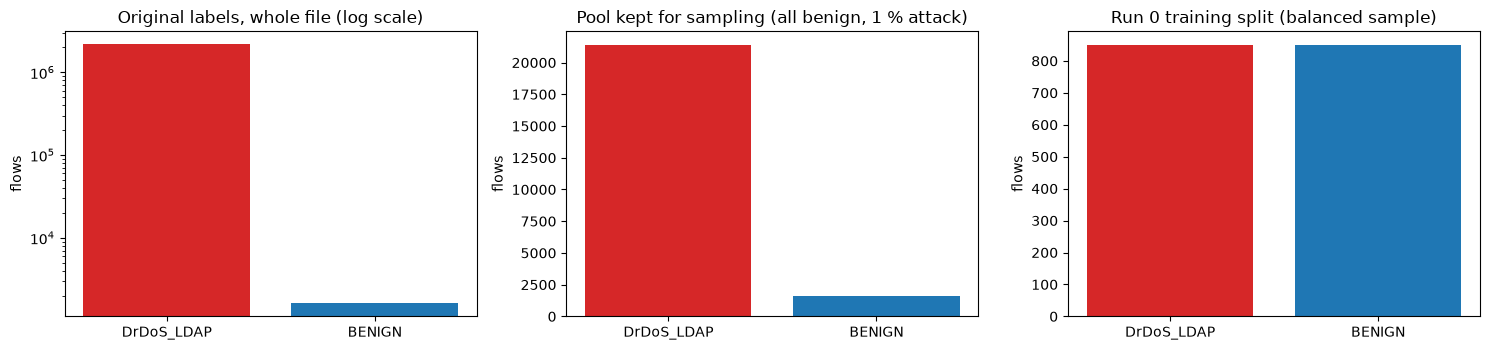

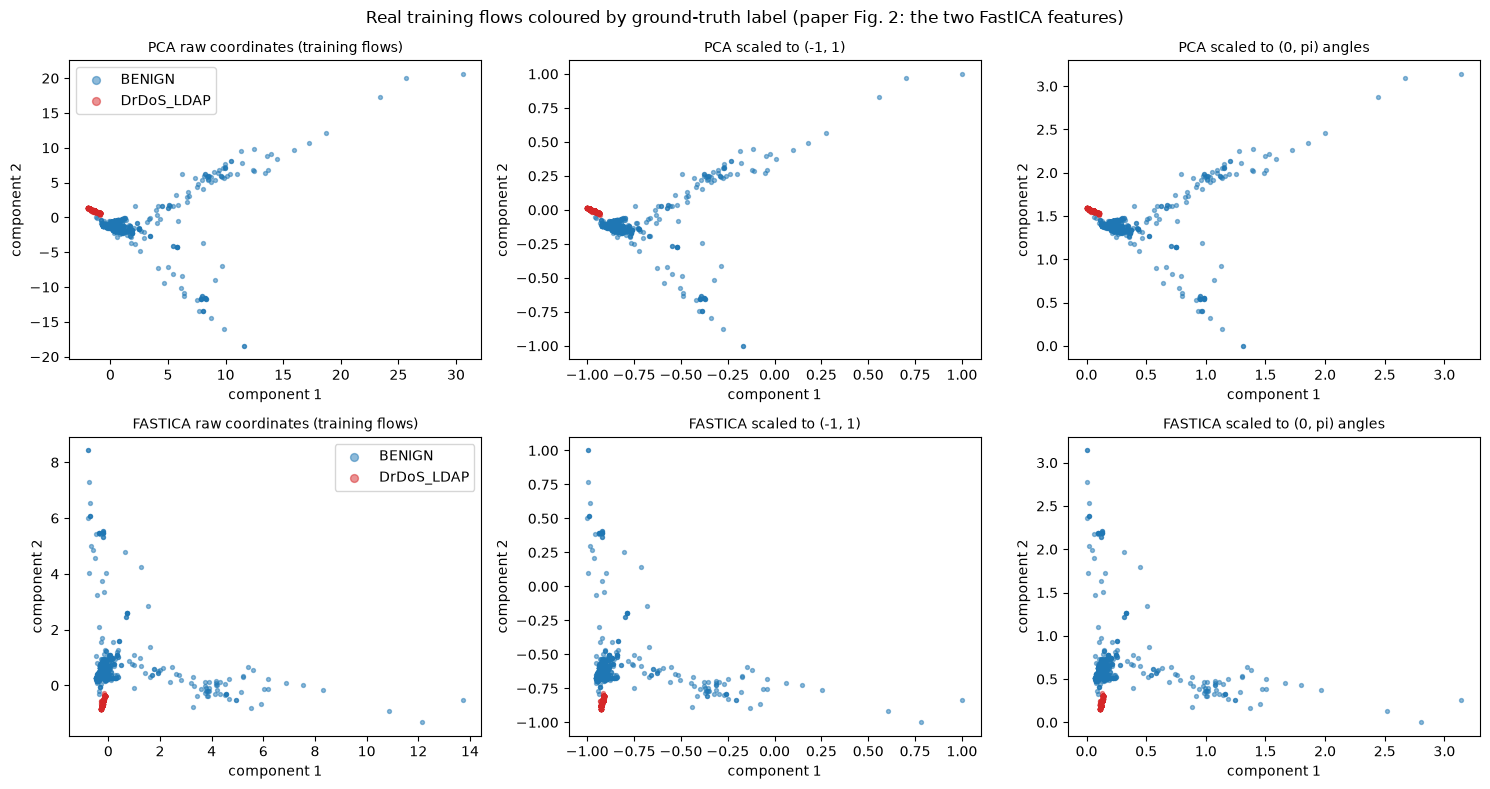

In [8]:
print("pool table:", pool.shape, "| after cleaning:", X_all.shape, "| model input after cleaning of run 0:", prep0["Z_train"].shape)
print("\nfeature names kept for run 0 (%d):" % len(prep0["cols"]))
print(", ".join(prep0["cols"]))
print("\noriginal label values and counts in the full file:", file_counts)
print("labels in the cached pool after cleaning:", lab_all.value_counts().to_dict())
print("run 0 training labels:", pd.Series(prep0["lab_train"]).value_counts().to_dict(), "| test labels:", pd.Series(prep0["lab_test"]).value_counts().to_dict())

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
cnt = pd.Series(file_counts).sort_values(ascending=False)
axes[0].bar(cnt.index, cnt.values, color=["tab:red" if k != "BENIGN" else "tab:blue" for k in cnt.index]); axes[0].set_yscale("log")
axes[0].set_title("Original labels, whole file (log scale)")
c2 = lab_all.value_counts()
axes[1].bar(c2.index, c2.values, color=["tab:red" if k != "BENIGN" else "tab:blue" for k in c2.index]); axes[1].set_title("Pool kept for sampling (all benign, 1 % attack)")
c3 = pd.Series(prep0["lab_train"]).value_counts()
axes[2].bar(c3.index, c3.values, color=["tab:red" if k != "BENIGN" else "tab:blue" for k in c3.index]); axes[2].set_title("Run 0 training split (balanced sample)")
for a in axes: a.set_ylabel("flows")
plt.tight_layout(); plt.show()

COL = {"BENIGN": "tab:blue"}
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for row, red in enumerate(("pca", "fastica")):
    panels = [(prep0["raw"][red][0], f"{red.upper()} raw coordinates (training flows)"),
              (prep0["enc"][(red, "pm1")][0], f"{red.upper()} scaled to (-1, 1)"),
              (prep0["enc"][(red, "pi")][0], f"{red.upper()} scaled to (0, pi) angles")]
    for ax, (P, title) in zip(axes[row], panels):
        for l in np.unique(prep0["lab_train"]):
            m = prep0["lab_train"] == l
            ax.scatter(P[m, 0], P[m, 1], s=8, alpha=0.5, c=COL.get(l, "tab:red"), label=l)
        ax.set_title(title, fontsize=10); ax.set_xlabel("component 1"); ax.set_ylabel("component 2")
    axes[row][0].legend(markerscale=2)
plt.suptitle("Real training flows coloured by ground-truth label (paper Fig. 2: the two FastICA features)"); plt.tight_layout(); plt.show()

### Is FastICA really different from PCA here?

The paper explains its gain by "PCA looks for uncorrelated variables, ICA for independent ones". With two components scikit-learn's `FastICA` first **whitens** the data (this is PCA followed by a rescaling to unit variance) and then only searches for a **rotation** of the two whitened axes. After `MinMaxScaler` has removed every per-axis scale, the two reductions can therefore differ only by a rotation (and axis order / sign) of the plane. The cell below checks this on the training flows: the FastICA scores are regressed on the whitened PCA scores, and the fitted 2 x 2 matrix should be orthogonal with a negligible residual.

In [9]:
Ptr_pca, Ptr_ica = prep0["raw"]["pca"][0], prep0["raw"]["fastica"][0]
W_pca = Ptr_pca / Ptr_pca.std(axis=0)                           # whitened PCA scores
Ws, *_ = np.linalg.lstsq(W_pca, Ptr_ica / Ptr_ica.std(axis=0), rcond=None)
resid = np.linalg.norm(W_pca @ Ws - Ptr_ica / Ptr_ica.std(axis=0)) / np.linalg.norm(Ptr_ica / Ptr_ica.std(axis=0))
print("fitted map from whitened PCA scores to FastICA scores:\n", np.round(Ws, 3))
print("orthogonality error ||W W^T - I||:", round(float(np.linalg.norm(Ws @ Ws.T - np.eye(2))), 4), "| relative residual:", round(float(resid), 4))
print("rotation angle (degrees):", round(float(np.degrees(np.arctan2(Ws[0, 1], Ws[0, 0]))), 1))

fitted map from whitened PCA scores to FastICA scores:
 [[ 0.822  0.57 ]
 [ 0.57  -0.822]]
orthogonality error ||W W^T - I||: 0.0 | relative residual: 0.0
rotation angle (degrees): 34.8


## 4. Classical baselines on identical inputs

The paper compares only with other quantum models. Here every encoding is also given to a classical RBF-SVM (scikit-learn defaults, and `C`, `gamma` tuned on the same inner validation split that tunes the quantum bandwidth) and to a random forest (200 trees). Both are also trained on all standardised features. Metrics are those of the paper's Table IV with the attack class as positive: accuracy, recall, precision, F-score and error rate (1 - accuracy).

In [10]:
def metrics(y, p):
    return dict(accuracy=accuracy_score(y, p), recall=recall_score(y, p, zero_division=0),
                precision=precision_score(y, p, zero_division=0), f1=f1_score(y, p, zero_division=0), error=1 - accuracy_score(y, p))

def inner_split(y, seed):
    return train_test_split(np.arange(len(y)), test_size=VAL_FRACTION, stratify=y, random_state=seed)

SVM_C_GRID, SVM_G_GRID = [1.0, 10.0, 100.0], [0.1, 1.0, 10.0]
def tuned_rbf(X, y, seed):
    itr, iva = inner_split(y, seed); best = None
    for C in SVM_C_GRID:
        for g in SVM_G_GRID:
            a = SVC(kernel="rbf", C=C, gamma=g).fit(X[itr], y[itr]).score(X[iva], y[iva])
            if best is None or a > best[0]: best = (a, C, g)
    return SVC(kernel="rbf", C=best[1], gamma=best[2]), best

def classical_rows(prep, run, seed):
    rows, preds = [], {}
    ytr, yte = prep["y_train"], prep["y_test"]
    sets = {(red, rg): (*prep["enc"][(red, rg)], red, rg) for red, rg in ENCODINGS}
    sets[("none", "all")] = (prep["Z_train"], prep["Z_test"], "all features", "standardised")
    for key, (Atr, Ate, red, rg) in sets.items():
        models = {"SVC-RBF default": SVC(kernel="rbf"), "RandomForest": RandomForestClassifier(n_estimators=200, random_state=seed)}
        tm, _ = tuned_rbf(Atr, ytr, seed); models["SVC-RBF tuned"] = tm
        for name, m in models.items():
            t0 = time.perf_counter(); p = m.fit(Atr, ytr).predict(Ate); dt = seconds_since(t0)
            rows.append(dict(run=run, family="classical", reduction=red, scaling=rg, model=name, variant="-", time_s=dt, **metrics(yte, p)))
            if run == 0: preds[(key, name)] = p
    return rows, preds

rows_c0, classical_preds0 = classical_rows(prep0, 0, SEED)
c0 = pd.DataFrame(rows_c0)
display(c0[["reduction", "scaling", "model", "accuracy", "recall", "precision", "f1", "error", "time_s"]].round(4))

,reduction,scaling,model,accuracy,recall,precision,f1,error,time_s
0,fastica,pm1,SVC-RBF default,1.0,1.0,1.0,1.0,0.0,0.1004
1,fastica,pm1,RandomForest,1.0,1.0,1.0,1.0,0.0,7.5776
2,fastica,pm1,SVC-RBF tuned,1.0,1.0,1.0,1.0,0.0,1.1183
3,pca,pm1,SVC-RBF default,1.0,1.0,1.0,1.0,0.0,0.1114
4,pca,pm1,RandomForest,1.0,1.0,1.0,1.0,0.0,7.8163
5,pca,pm1,SVC-RBF tuned,1.0,1.0,1.0,1.0,0.0,0.3239
6,fastica,pi,SVC-RBF default,1.0,1.0,1.0,1.0,0.0,0.0502
7,fastica,pi,RandomForest,1.0,1.0,1.0,1.0,0.0,7.6244
8,fastica,pi,SVC-RBF tuned,1.0,1.0,1.0,1.0,0.0,0.2399
9,pca,pi,SVC-RBF default,1.0,1.0,1.0,1.0,0.0,0.1226


Every classical model is perfect or nearly perfect, even on two numbers. Before trusting a comparison of kernels on this task it is worth knowing why. The cell below trains a one-split decision stump on each single standardised feature of run 0 and lists the best ones.

In [11]:
from sklearn.tree import DecisionTreeClassifier
stump = []
for j, c in enumerate(prep0["cols"]):
    st = DecisionTreeClassifier(max_depth=1, random_state=SEED).fit(prep0["Z_train"][:, [j]], prep0["y_train"])
    stump.append((c, st.score(prep0["Z_test"][:, [j]], prep0["y_test"])))
stump = pd.DataFrame(stump, columns=["feature", "test accuracy of a one-split stump"]).sort_values("test accuracy of a one-split stump", ascending=False)
display(stump.head(8).round(3).reset_index(drop=True))
print(f"{int((stump.iloc[:, 1] >= 0.9).sum())} of {len(stump)} single features separate the 200 test flows with at least 90 % accuracy")

,feature,test accuracy of a one-split stump
0,Flow Bytes/s,0.995
1,Total Length of Fwd Packets,0.965
2,Max Packet Length,0.955
3,Inbound,0.895
4,Flow IAT Std,0.880
5,Protocol,0.880
6,Flow Duration,0.850
7,Flow Packets/s,0.850


3 of 39 single features separate the 200 test flows with at least 90 % accuracy


## Quantum Circuit Architecture

The model has no trainable circuit parameters: the circuit only **encodes** a flow `x = (x0, x1)` into a two-qubit state, and the classifier is a classical weight vector (the Pegasos coefficients) on the kernel. The circuit that is executed is Qiskit's `zz_feature_map(2, reps=4)`: per repetition a Hadamard on each qubit, a phase gate `P(2 x_i)` on each qubit, and one entangling block CX - `P(2 (pi - x0)(pi - x1))` - CX between the two qubits (the paper's Eqs. 9-12). The kernel entry `K(x, z) = |<phi(x)|phi(z)>|^2` is the probability of measuring `00` after `U(x)` followed by `U(z)^dagger` (second drawing, the circuit that a quantum computer would run and that the noisy proxy of Section 9 simulates).

Assumption: the paper's Fig. 4 shows additional "X shifting gates" and a measurement block that Qiskit's `ZZFeatureMap` does not contain; the executed circuit is the library's map with its default data map, as the paper's Eqs. 5 and 9 state.

feature map: 2 qubits | depth 20 | gate counts {'p': 12, 'h': 8, 'cx': 8} | input parameters 2 | trainable parameters: 0 (kernel method)


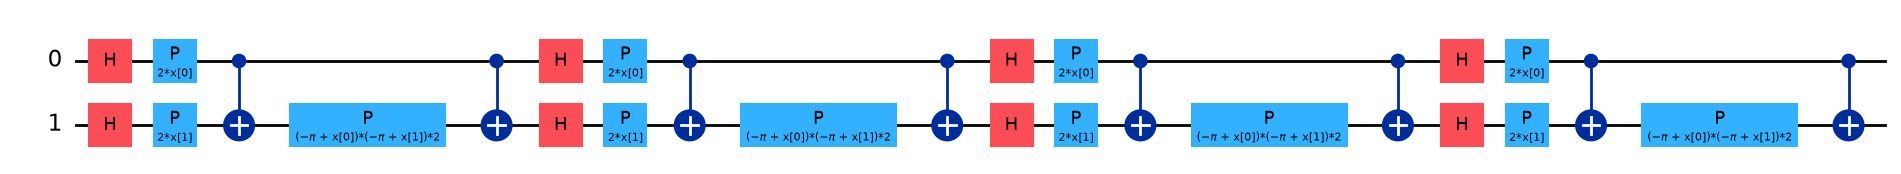

compute-uncompute kernel circuit: 2 qubits | depth 41 | parameters 4


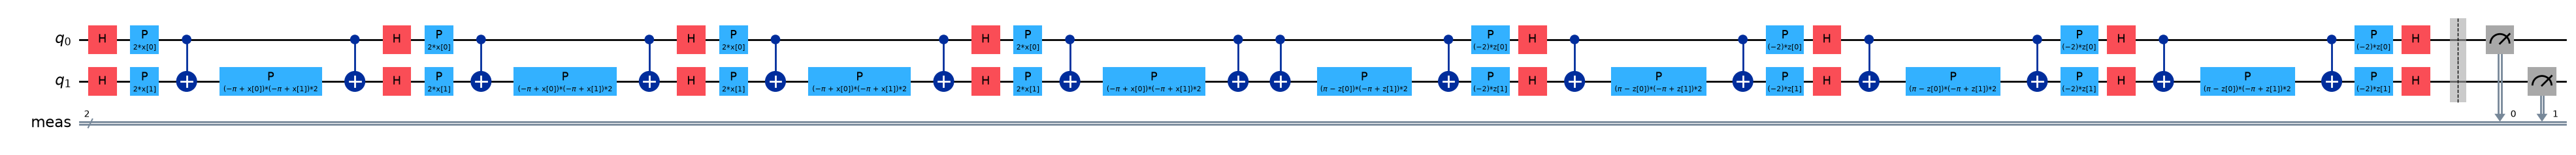

the vectorised simulator reproduces Qiskit's Statevector of the drawn circuit for 40 random inputs (np.allclose passed)


In [12]:
fm = zz_feature_map(N_QUBITS, reps=ZZ_REPS, entanglement=ENTANGLEMENT)
x_demo = prep0["enc"][("fastica", "pm1")][0][0]
bound = fm.assign_parameters(x_demo)
print("feature map:", fm.num_qubits, "qubits | depth", fm.depth(), "| gate counts", dict(fm.count_ops()),
      "| input parameters", fm.num_parameters, "| trainable parameters: 0 (kernel method)")
display(fm.draw("mpl", fold=60))

xs, zs = ParameterVector("x", N_QUBITS), ParameterVector("z", N_QUBITS)
kernel_template = QuantumCircuit(N_QUBITS)
kernel_template.compose(fm.assign_parameters(list(xs)), inplace=True)
kernel_template.compose(fm.assign_parameters(list(zs)).inverse(), inplace=True)
kernel_template.measure_all()
print("compute-uncompute kernel circuit:", kernel_template.num_qubits, "qubits | depth", kernel_template.depth(), "| parameters", kernel_template.num_parameters)
display(kernel_template.draw("mpl", fold=70))

# --- a vectorised statevector simulator of exactly this circuit, used for all the repeated runs (tiny: 2 qubits) ---
_H = np.array([[1, 1], [1, -1]]) / np.sqrt(2); _H2 = np.kron(_H, _H)
_b = np.arange(4); _b0, _b1 = _b & 1, (_b >> 1) & 1                     # qubit 0 is the least significant bit (Qiskit order)
def zz_states(A, reps=ZZ_REPS):
    # |phi(x)> = (D(x) H^2)^reps |00>, D(x) = diagonal of P(2x0) P(2x1) CX P(2(pi-x0)(pi-x1)) CX
    A = np.atleast_2d(A)
    th = 2 * (np.pi - A[:, 0]) * (np.pi - A[:, 1])
    D = np.exp(1j * (2 * A[:, [0]] * _b0 + 2 * A[:, [1]] * _b1 + th[:, None] * (_b0 ^ _b1)))
    psi = np.zeros((len(A), 4), complex); psi[:, 0] = 1
    for _ in range(reps):
        psi = D * (psi @ _H2.T)
    return psi
def fidelity(SA, SB): return np.abs(SA.conj() @ SB.T) ** 2

test_pts = np.random.default_rng(0).uniform(-3, 3, (40, 2))
S_qiskit = np.array([Statevector(fm.assign_parameters(a)).data for a in test_pts])
assert np.allclose(zz_states(test_pts), S_qiskit, atol=1e-10), "vectorised simulator differs from Qiskit"
print("the vectorised simulator reproduces Qiskit's Statevector of the drawn circuit for 40 random inputs (np.allclose passed)")

## 5. The quantum kernel, the Pegasos solver and the dual solver

**Kernel.** `K(x, z) = |<phi(x)|phi(z)>|^2` (paper Eq. 15 / 20). Because the inputs have two components, the states have four amplitudes, so the whole kernel matrix is one matrix product of statevectors. A **bandwidth** `b` multiplies the angles before they enter the circuit (`phi(b x)`); with `reps = 4` large angles make all states almost orthogonal, so the bandwidth is chosen on an inner validation split of the training data.

**Pegasos** (Algorithm II of the paper, Shalev-Shwartz et al.): start with `alpha = 0`; for `t = 1 ... T` draw a random training index `i`, and if `y_i * (C / t) * sum_j alpha_j y_j K(x_i, x_j) < 1` increase `alpha_i` by one. Qiskit's `PegasosQSVC` adds a constant 1 to every kernel value as an implicit bias and maps the smaller label to +1; `pegasos_fit` below does the same with the same random generator (`np.random.default_rng(seed)`), so it can be compared prediction by prediction with Qiskit's class in Section 8.

**Dual QSVC.** `SVC(kernel="precomputed", C)`, i.e. the quadratic programme of Eq. 13, which is what Qiskit's `QSVC`/`QSVM` solves (the paper's "QSVM").

In [13]:
def pegasos_fit(K1, y, C, steps, seed):
    # K1 = kernel + 1 (Qiskit's implicit bias); labels {0,1} -> {+1,-1} exactly as PegasosQSVC does
    ypm = np.where(y == 0, 1.0, -1.0); n = len(y); alpha = np.zeros(n); g = np.random.default_rng(seed)
    for t in range(1, steps + 1):
        i = int(g.integers(0, n))
        if ypm[i] * C / t * (K1[i] @ (alpha * ypm)) < 1:
            alpha[i] += 1
    return alpha * ypm

def attack_score(trainer, model, K):
    # positive score = attack (label 1)
    return model.decision_function(K) if trainer == "dual" else -((K + 1.0) @ model)

def fit_model(trainer, K, y, C, steps, seed):
    return SVC(kernel="precomputed", C=C).fit(K, y) if trainer == "dual" else pegasos_fit(K + 1.0, y, C, steps, seed)

class QuantumKernelClassifier:
    """angles -> bandwidth -> ZZ states -> fidelity kernel -> dual SVC or Pegasos"""
    def __init__(self, trainer, bw, C, steps, seed): self.trainer, self.bw, self.C, self.steps, self.seed = trainer, bw, C, steps, seed
    def fit(self, A, y):
        self.S = zz_states(A * self.bw); self.model = fit_model(self.trainer, fidelity(self.S, self.S), y, self.C, self.steps, self.seed); return self
    def score(self, A): return attack_score(self.trainer, self.model, fidelity(zz_states(A * self.bw), self.S))
    def predict(self, A): return (self.score(A) > 0).astype(int)

def grid_for(trainer):
    if trainer == "dual": return [dict(C=C, steps=0) for C in DUAL_C_GRID]
    return [dict(C=C, steps=s) for C in PEG_C_GRID for s in PEG_STEPS_GRID]

def tune(trainer, A, y, seed):
    # CHOICE: bandwidth + solver settings chosen by accuracy on an inner validation split of the training data;
    # ties go to the first grid entry (grids start with the paper / Qiskit default). The test split is never used.
    itr, iva = inner_split(y, seed); table, best = [], None
    for bw in BW_GRID:
        S = zz_states(A * bw); K = fidelity(S, S)
        for p in grid_for(trainer):
            m = fit_model(trainer, K[np.ix_(itr, itr)], y[itr], p["C"], p["steps"], seed)
            acc = float(((attack_score(trainer, m, K[np.ix_(iva, itr)]) > 0).astype(int) == y[iva]).mean())
            table.append(dict(bw=bw, **p, val_accuracy=acc, mean_offdiag=float(K[~np.eye(len(K), dtype=bool)].mean())))
            if best is None or acc > best[0]: best = (acc, bw, p)
    return dict(bw=best[1], **best[2]), best[0], pd.DataFrame(table)

TRAINERS = {"Pegasos": "pegasos", "Dual QSVC": "dual"}
def quantum_rows(prep, run, seed, keep_models=False):
    rows, models, tunes = [], {}, {}
    ytr, yte = prep["y_train"], prep["y_test"]
    for (red, rg) in ENCODINGS:
        Atr, Ate = prep["enc"][(red, rg)]
        for mname, trainer in TRAINERS.items():
            default = dict(bw=1.0, C=PEG_C_DEFAULT if trainer == "pegasos" else DUAL_C_DEFAULT, steps=PEG_STEPS_DEFAULT if trainer == "pegasos" else 0)
            t0 = time.perf_counter(); best, val_acc, tbl = tune(trainer, Atr, ytr, seed); t_tune = seconds_since(t0)
            tunes[(red, rg, mname)] = tbl
            for variant, par in (("as-published", default), ("tuned", best)):
                t0 = time.perf_counter()
                clf = QuantumKernelClassifier(trainer, par["bw"], par["C"], par["steps"], seed).fit(Atr, ytr)
                p = clf.predict(Ate); dt = seconds_since(t0)
                rows.append(dict(run=run, family="quantum", reduction=red, scaling=rg, model=mname, variant=variant, time_s=dt, tune_s=t_tune,
                                 bw=par["bw"], C=par["C"], steps=par["steps"], inner_val=val_acc if variant == "tuned" else np.nan, **metrics(yte, p)))
                if keep_models: models[(red, rg, mname, variant)] = (clf, p)
    return rows, models, tunes

## 6. Training and testing the eight quantum variants (run 0 = the paper-like single run)

Run 0 is one random draw and one split, as in the paper. Each combination of reduction (FastICA / PCA), angle range ((-1, 1) / (0, pi)) and trainer (Pegasos / dual QSVC) is trained twice: **as-published** (bandwidth 1, Qiskit-tutorial settings) and **tuned** on the inner validation split. The validation sweep of the bandwidth is drawn afterwards.

In [14]:
t0 = time.perf_counter()
rows_q0, models0, tunes0 = quantum_rows(prep0, 0, SEED, keep_models=True)
print(f"run 0 finished in {seconds_since(t0):.0f} s")
q0 = pd.DataFrame(rows_q0)
display(q0[["reduction", "scaling", "model", "variant", "bw", "C", "steps", "accuracy", "recall", "precision", "f1", "error", "time_s"]].round(4))

run 0 finished in 174 s


,reduction,scaling,model,variant,bw,C,steps,accuracy,recall,precision,f1,error,time_s
0,fastica,pm1,Pegasos,as-published,1.00,1000.0,1000,1.000,1.00,1.0000,1.0000,0.000,0.2803
1,fastica,pm1,Pegasos,tuned,1.00,1000.0,1000,1.000,1.00,1.0000,1.0000,0.000,0.2713
2,fastica,pm1,Dual QSVC,as-published,1.00,1.0,0,1.000,1.00,1.0000,1.0000,0.000,2.3095
3,fastica,pm1,Dual QSVC,tuned,1.00,1.0,0,1.000,1.00,1.0000,1.0000,0.000,2.7245
4,pca,pm1,Pegasos,as-published,1.00,1000.0,1000,1.000,1.00,1.0000,1.0000,0.000,5.1125
5,pca,pm1,Pegasos,tuned,1.00,100.0,1000,0.995,1.00,0.9901,0.9950,0.005,4.0920
6,pca,pm1,Dual QSVC,as-published,1.00,1.0,0,1.000,1.00,1.0000,1.0000,0.000,1.6639
7,pca,pm1,Dual QSVC,tuned,1.00,1.0,0,1.000,1.00,1.0000,1.0000,0.000,3.1776
8,fastica,pi,Pegasos,as-published,1.00,1000.0,1000,0.990,0.98,1.0000,0.9899,0.010,3.8779
9,fastica,pi,Pegasos,tuned,0.25,1000.0,1000,0.980,1.00,0.9615,0.9804,0.020,1.8417


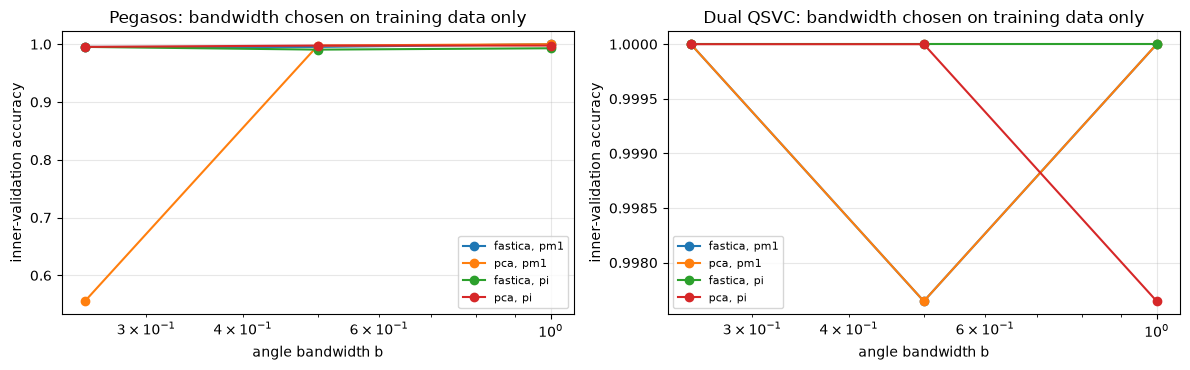

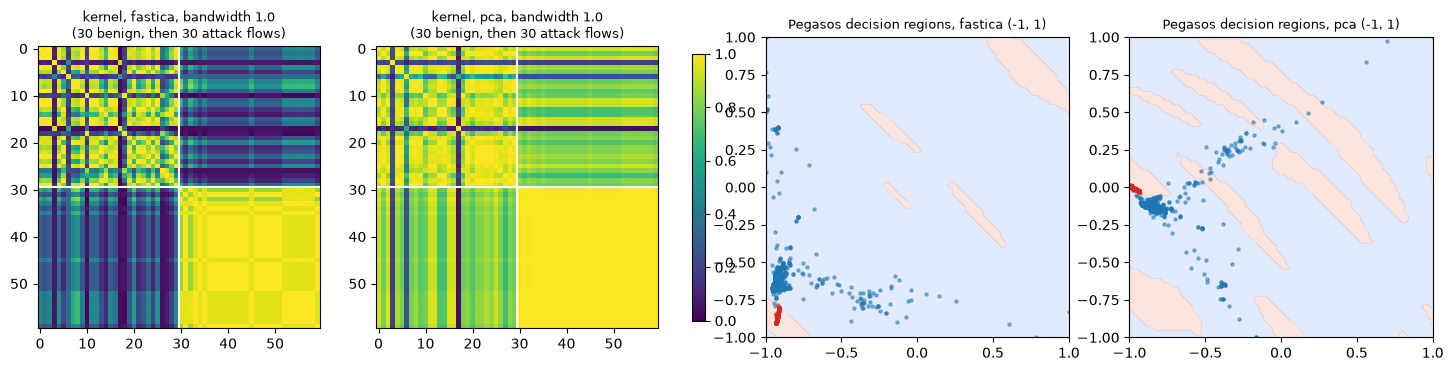

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, mname in zip(axes, TRAINERS):
    for (red, rg) in ENCODINGS:
        g = tunes0[(red, rg, mname)].groupby("bw")["val_accuracy"].max()
        ax.plot(g.index, g.values, "o-", label=f"{red}, {rg}")
    ax.set_xscale("log"); ax.set_xlabel("angle bandwidth b"); ax.set_ylabel("inner-validation accuracy"); ax.set_title(f"{mname}: bandwidth chosen on training data only")
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# kernel heat-maps (30 benign then 30 attack training flows) and decision regions for the two (-1, 1) encodings
fig, axes = plt.subplots(1, 4, figsize=(18, 3.9))
for k, (red, rg) in enumerate([("fastica", "pm1"), ("pca", "pm1")]):
    A = prep0["enc"][(red, rg)][0]; y = prep0["y_train"]
    sub = np.r_[np.where(y == 0)[0][:30], np.where(y == 1)[0][:30]]
    bw = models0[(red, rg, "Pegasos", "tuned")][0].bw
    S = zz_states(A[sub] * bw); im = axes[k].imshow(fidelity(S, S), cmap="viridis", vmin=0, vmax=1)
    axes[k].axhline(29.5, color="w"); axes[k].axvline(29.5, color="w"); axes[k].set_title(f"kernel, {red}, bandwidth {bw}\n(30 benign, then 30 attack flows)", fontsize=9)
    clf = models0[(red, rg, "Pegasos", "tuned")][0]
    g = np.linspace(-1, 1, 70); GX, GY = np.meshgrid(g, g); G = np.c_[GX.ravel(), GY.ravel()]
    ax = axes[2 + k]; ax.contourf(GX, GY, (clf.predict(G)).reshape(GX.shape), alpha=0.25, cmap="coolwarm", levels=[-0.5, 0.5, 1.5])
    for l, c in ((0, "tab:blue"), (1, "tab:red")):
        m = y == l; ax.scatter(A[m, 0], A[m, 1], s=5, c=c, alpha=0.5)
    ax.set_title(f"Pegasos decision regions, {red} (-1, 1)", fontsize=9)
fig.colorbar(im, ax=axes[:2], fraction=0.02); plt.show()

## 7. Repeated runs: how much of Table IV is luck?

The paper reports one run on 200 test flows, where one flow is worth 0.5 accuracy points. The loop below repeats the whole pipeline (new balanced draw, new split, new FastICA, new tuning, new Pegasos random indices) for `N_RUNS` seeds and reports mean +- std. Run 0 above is included.

In [16]:
t0 = time.perf_counter()
all_rows = list(rows_q0) + list(rows_c0)
for run in range(1, N_RUNS):
    trr, ter = draw(SEED + run)
    prep = prepare(trr, ter, SEED + run)
    rq, _, _ = quantum_rows(prep, run, SEED + run); rc, _ = classical_rows(prep, run, SEED + run)
    all_rows += rq + rc
    print(f"run {run}: done ({seconds_since(t0):.0f} s elapsed)")
res = pd.DataFrame(all_rows)
METRICS = ["accuracy", "recall", "precision", "f1", "error"]
summary = res.groupby(["family", "reduction", "scaling", "model", "variant"])[METRICS + ["time_s"]].agg(["mean", "std"]).round(4)
display(summary)

run 1: done (240 s elapsed)


run 2: done (420 s elapsed)


accuracy          recall         precision              f1           error           time_s        
                                                                     mean     std    mean     std      mean     std    mean     std    mean     std     mean     std
family    reduction    scaling      model           variant                                                                                                         
classical all features standardised RandomForest    -              1.0000  0.0000  1.0000  0.0000    1.0000  0.0000  1.0000  0.0000  0.0000  0.0000   4.5260  2.8168
                                    SVC-RBF default -              1.0000  0.0000  1.0000  0.0000    1.0000  0.0000  1.0000  0.0000  0.0000  0.0000   0.2233  0.1476
                                    SVC-RBF tuned   -              1.0000  0.0000  1.0000  0.0000    1.0000  0.0000  1.0000  0.0000  0.0000  0.0000   0.1761  0.0441
          fastica      pi           RandomForest    -              1.0000  0.0000  1.0000  0.0000    1.0000  0.0000  1.0000  0.0000  0.0000  0.0000   6.8762  1.5086
                                    SVC-RBF default -              1.0000  0.0000  1.0000  0.0000    1.0000  0.0000  1.0000  0.0000  0.0000  0.0000   0.0601  0.0409
                                    SVC-RBF tuned   -              1.0000  0.0000  1.0000  0.0000    1.0000  0.0000  1.0000  0.0000  0.0000  0.0000   0.1721  0.1047
                       pm1          RandomForest    -              1.0000  0.0000  1.0000  0.0000    1.0000  0.0000  1.0000  0.0000  0.0000  0.0000   7.2603  3.7681
                                    SVC-RBF default -              1.0000  0.0000  1.0000  0.0000    1.0000  0.0000  1.0000  0.0000  0.0000  0.0000   0.0667  0.0482
                                    SVC-RBF tuned   -              1.0000  0.0000  1.0000  0.0000    1.0000  0.0000  1.0000  0.0000  0.0000  0.0000   0.4242  0.6013
          pca          pi           RandomForest    -              1.0000  0.0000  1.0000  0.0000    1.0000  0.0000  1.0000  0.0000  0.0000  0.0000   7.0234  3.6064
                                    SVC-RBF default -              1.0000  0.0000  1.0000  0.0000    1.0000  0.0000  1.0000  0.0000  0.0000  0.0000   0.0921  0.0612
                                    SVC-RBF tuned   -              1.0000  0.0000  1.0000  0.0000    1.0000  0.0000  1.0000  0.0000  0.0000  0.0000   0.6185  0.6391
                       pm1          RandomForest    -              1.0000  0.0000  1.0000  0.0000    1.0000  0.0000  1.0000  0.0000  0.0000  0.0000  10.6749  2.9062
                                    SVC-RBF default -              1.0000  0.0000  1.0000  0.0000    1.0000  0.0000  1.0000  0.0000  0.0000  0.0000   0.1143  0.0205
                                    SVC-RBF tuned   -              1.0000  0.0000  1.0000  0.0000    1.0000  0.0000  1.0000  0.0000  0.0000  0.0000   0.2371  0.1829
quantum   fastica      pi           Dual QSVC       as-published   1.0000  0.0000  1.0000  0.0000    1.0000  0.0000  1.0000  0.0000  0.0000  0.0000   1.3383  0.4752
                                                    tuned          1.0000  0.0000  1.0000  0.0000    1.0000  0.0000  1.0000  0.0000  0.0000  0.0000   1.9955  0.8593
                                    Pegasos         as-published   0.9967  0.0058  0.9933  0.0115    1.0000  0.0000  0.9966  0.0058  0.0033  0.0058   2.3167  1.3805
                                                    tuned          0.9917  0.0104  1.0000  0.0000    0.9839  0.0200  0.9918  0.0102  0.0083  0.0104   1.5191  0.2941
                       pm1          Dual QSVC       as-published   1.0000  0.0000  1.0000  0.0000    1.0000  0.0000  1.0000  0.0000  0.0000  0.0000   3.0222  0.6864
                                                    tuned          1.0000  0.0000  1.0000  0.0000    1.0000  0.0000  1.0000  0.0000  0.0000  0.0000   2.5673  0.4765
                                    Pegasos         as-published   0.9983  0.0029  0.9967  0.0058    1.00

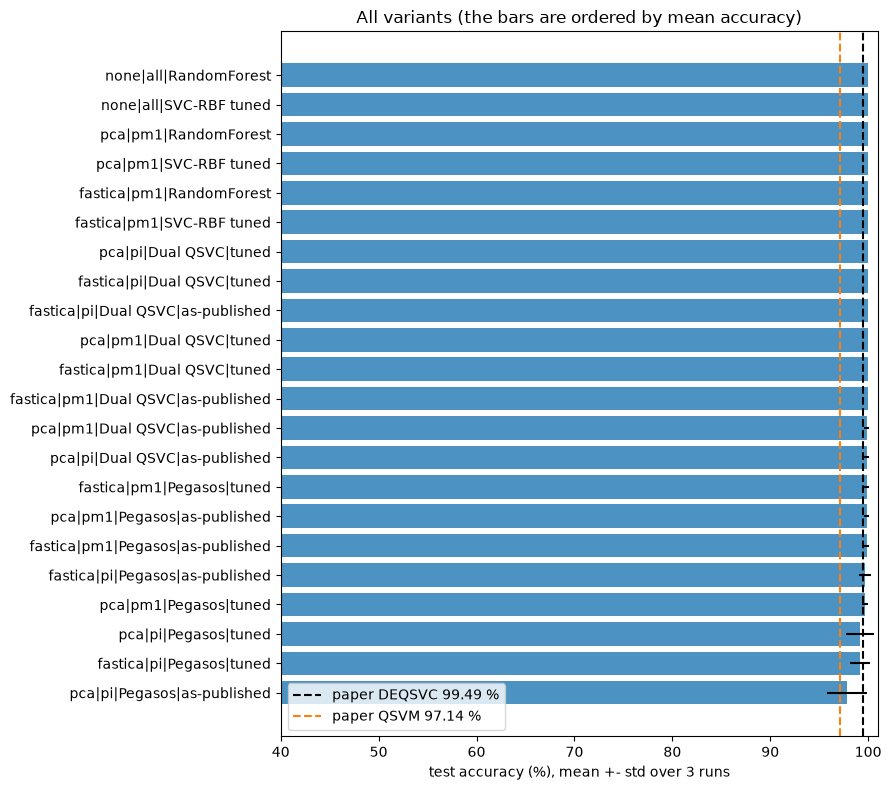

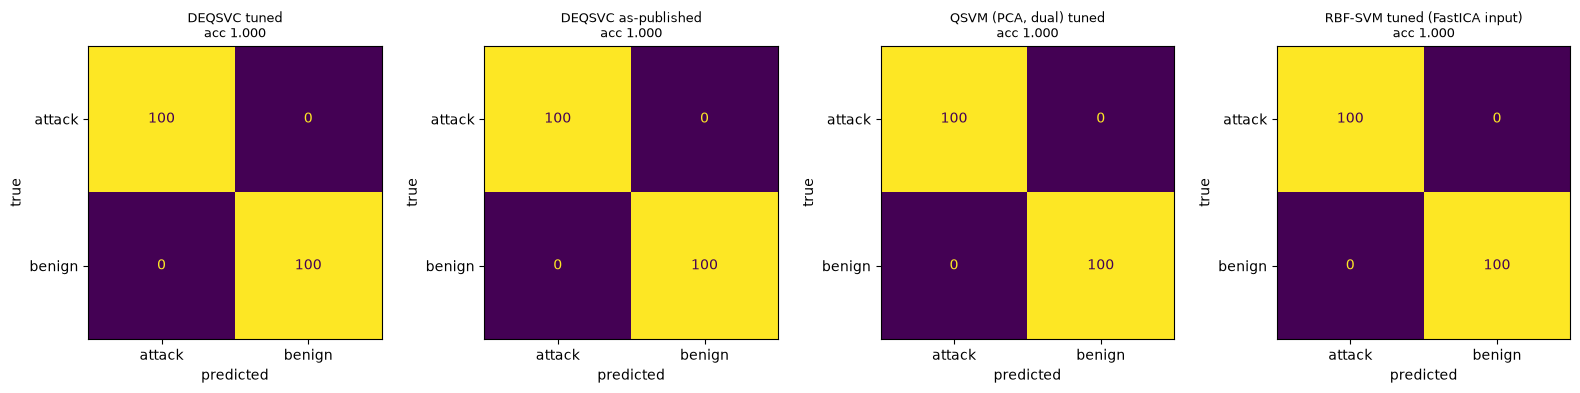

In [17]:
def pick(df=None, **kw):
    d = res if df is None else df
    for k, v in kw.items(): d = d[d[k] == v]
    return d
def mean_of(metric, **kw): return float(pick(**kw)[metric].mean())

labels, means, stds = [], [], []
for (red, rg) in ENCODINGS:
    for mname in TRAINERS:
        for variant in ("as-published", "tuned"):
            d = pick(family="quantum", reduction=red, scaling=rg, model=mname, variant=variant)
            labels.append(f"{red}|{rg}|{mname}|{variant}"); means.append(d.accuracy.mean() * 100); stds.append(d.accuracy.std() * 100)
for (red, rg) in ENCODINGS[:2] + [("none", "all")]:
    for mname in ("SVC-RBF tuned", "RandomForest"):
        d = pick(family="classical", reduction=("all features" if red == "none" else red), scaling=("standardised" if red == "none" else rg), model=mname)
        labels.append(f"{red}|{rg}|{mname}"); means.append(d.accuracy.mean() * 100); stds.append(d.accuracy.std() * 100)
order = np.argsort(means)
plt.figure(figsize=(9, 8)); plt.barh(np.array(labels)[order], np.array(means)[order], xerr=np.array(stds)[order], color="tab:blue", alpha=0.8)
plt.axvline(99.49, color="k", ls="--", label="paper DEQSVC 99.49 %"); plt.axvline(97.14, color="tab:orange", ls="--", label="paper QSVM 97.14 %")
plt.xlabel(f"test accuracy (%), mean +- std over {N_RUNS} runs"); plt.xlim(40, 101); plt.legend(loc="lower left"); plt.title("All variants (the bars are ordered by mean accuracy)")
plt.tight_layout(); plt.show()

# confusion matrices of run 0 for DEQSVC and its closest relatives (attack = positive class)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
items = [("DEQSVC tuned", models0[("fastica", "pm1", "Pegasos", "tuned")][1]), ("DEQSVC as-published", models0[("fastica", "pm1", "Pegasos", "as-published")][1]),
         ("QSVM (PCA, dual) tuned", models0[("pca", "pm1", "Dual QSVC", "tuned")][1]), ("RBF-SVM tuned (FastICA input)", classical_preds0[(("fastica", "pm1"), "SVC-RBF tuned")])]
for ax, (name, p) in zip(axes, items):
    ConfusionMatrixDisplay(confusion_matrix(prep0["y_test"], p, labels=[1, 0]), display_labels=["attack", "benign"]).plot(ax=ax, colorbar=False)
    ax.set_title(f"{name}\nacc {accuracy_score(prep0['y_test'], p):.3f}", fontsize=9); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.show()

### Sensitivity analysis: the same experiment without the two near-label columns

On this file nearly every variant reaches 100 %, so the experiment cannot rank the variants. The stump table above shows that single columns such as `Inbound` (the direction flag of the capture) and `Protocol` already separate the classes. As a sensitivity analysis on the same real flows, the cell below removes these two columns (and nothing else, `DROP_SENS`) and repeats the whole experiment for `N_SENS` runs. This is **not** the paper's setting; it only asks whether the ranking of the variants changes when the task is a little harder.

sensitivity run 0: done (262 s elapsed), 37 features kept


sensitivity run 1: done (542 s elapsed), 37 features kept


sensitivity run 2: done (706 s elapsed), 37 features kept


accuracy              f1        
                                                                     mean     std    mean     std
family    reduction    scaling      model           variant                                      
classical all features standardised RandomForest    -              1.0000  0.0000  1.0000  0.0000
                                    SVC-RBF default -              1.0000  0.0000  1.0000  0.0000
                                    SVC-RBF tuned   -              1.0000  0.0000  1.0000  0.0000
          fastica      pi           RandomForest    -              1.0000  0.0000  1.0000  0.0000
                                    SVC-RBF default -              1.0000  0.0000  1.0000  0.0000
                                    SVC-RBF tuned   -              0.9983  0.0029  0.9983  0.0029
                       pm1          RandomForest    -              1.0000  0.0000  1.0000  0.0000
                                    SVC-RBF default -              1.0000  0.0000  1.0000  0.0000
                                    SVC-RBF tuned   -              0.9983  0.0029  0.9983  0.0029
          pca          pi           RandomForest    -              1.0000  0.0000  1.0000  0.0000
                                    SVC-RBF default -              1.0000  0.0000  1.0000  0.0000
                                    SVC-RBF tuned   -              1.0000  0.0000  1.0000  0.0000
                       pm1          RandomForest    -              1.0000  0.0000  1.0000  0.0000
                                    SVC-RBF default -              1.0000  0.0000  1.0000  0.0000
                                    SVC-RBF tuned   -              1.0000  0.0000  1.0000  0.0000
quantum   fastica      pi           Dual QSVC       as-published   0.9933  0.0076  0.9934  0.0075
                                                    tuned          1.0000  0.0000  1.0000  0.0000
                                    Pegasos         as-published   0.9833  0.0247  0.9826  0.0259
                                                    tuned          0.9950  0.0087  0.9951  0.0085
                       pm1          Dual QSVC       as-published   0.9817  0.0275  0.9810  0.0287
                                                    tuned          0.9983  0.0029  0.9983  0.0029
                                    Pegasos         as-published   0.9817  0.0275  0.9810  0.0287
                                                    tuned          0.9800  0.0304  0.9809  0.0288
          pca          pi           Dual QSVC       as-published   0.9983  0.0029  0.9983  0.0029
                                                    tuned          1.0000  0.0000  1.0000  0.0000
                                    Pegasos         as-published   0.9800  0.0218  0.9793  0.0230
                                                    tuned          0.9933  0.0076  0.9934  0.0075
                       pm1          Dual QSVC       as-published   0.9950  0.0050  0.9950  0.0050
                                                    tuned          1.0000  0.0000  1.0000  0.0000
                                    Pegasos         as-published   0.9717  0.0144  0.9712  0.0159
                                                    tuned          1.0000  0.0000  1.0000  0.0000

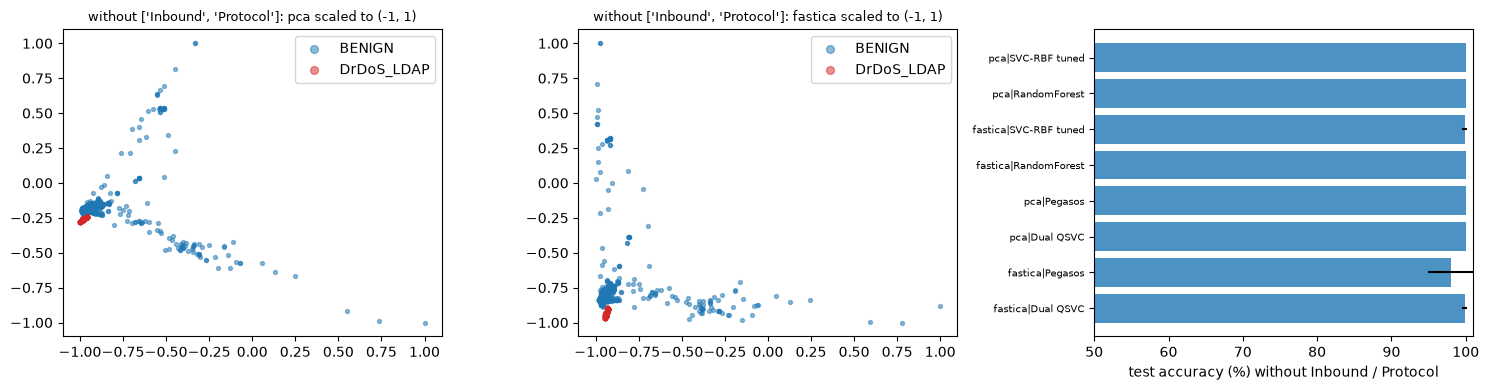

In [18]:
DROP_SENS = ["Inbound", "Protocol"]
sens_rows = []
t0 = time.perf_counter()
for run in range(N_SENS):
    trr, ter = draw(SEED + run)
    prep_s = prepare(trr, ter, SEED + run, exclude=DROP_SENS)
    if run == 0: prep_s0 = prep_s
    rq, _, _ = quantum_rows(prep_s, run, SEED + run); rc, _ = classical_rows(prep_s, run, SEED + run)
    sens_rows += rq + rc
    print(f"sensitivity run {run}: done ({seconds_since(t0):.0f} s elapsed), {len(prep_s['cols'])} features kept")
res_s = pd.DataFrame(sens_rows)
sens_summary = res_s.groupby(["family", "reduction", "scaling", "model", "variant"])[["accuracy", "f1"]].agg(["mean", "std"]).round(4)
display(sens_summary)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (red, rg) in zip(axes, [("pca", "pm1"), ("fastica", "pm1")]):
    A = prep_s0["enc"][(red, rg)][0]
    for l in np.unique(prep_s0["lab_train"]):
        m = prep_s0["lab_train"] == l; ax.scatter(A[m, 0], A[m, 1], s=8, alpha=0.5, c=COL.get(l, "tab:red"), label=l)
    ax.set_title(f"without {DROP_SENS}: {red} scaled to (-1, 1)", fontsize=9); ax.legend(markerscale=2)
d = res_s[(res_s.family == "quantum") & (res_s.scaling == "pm1") & (res_s.variant == "tuned")].groupby(["reduction", "model"])["accuracy"].agg(["mean", "std"])
cl = res_s[(res_s.family == "classical") & (res_s.scaling == "pm1") & (res_s.model.isin(["SVC-RBF tuned", "RandomForest"]))].groupby(["reduction", "model"])["accuracy"].agg(["mean", "std"])
both = pd.concat([d, cl]); axes[2].barh([f"{a}|{b}" for a, b in both.index], both["mean"] * 100, xerr=both["std"].fillna(0) * 100, color="tab:blue", alpha=0.8)
axes[2].set_xlim(50, 101); axes[2].set_xlabel("test accuracy (%) without Inbound / Protocol"); axes[2].tick_params(axis="y", labelsize=7)
plt.tight_layout(); plt.show()

## 8. Cross-check with Qiskit's own classes and the wall-clock comparison

Everything above used the vectorised simulator. Here the same experiment on run 0 goes through the classes the paper names:

1. `FidelityStatevectorKernel(feature_map=fm)` (the modern replacement of `QuantumKernel` + `QuantumInstance(statevector_simulator)`) must give the same kernel matrix (`np.allclose`);
2. `QSVC` with that kernel must predict exactly what `SVC(kernel="precomputed")` predicts;
3. `PegasosQSVC(quantum_kernel=..., C, num_steps, seed)` must predict exactly what `pegasos_fit` predicts (same seed, same random indices).

The times of the Qiskit route are also the closest this notebook gets to Table IV's wall-clock column (the paper's 92 s and 190 s were measured on a Dell Core i5). Qiskit's classes evaluate the kernel flow by flow in Python, so steps 2 and 3 use `QISKIT_CHECK_N` training flows (and, in `FAST_MODE`, 300 Pegasos steps) instead of the full 1700 flows; the vectorised route is timed on all 1700.

Qiskit kernel of 150 flows in 7.8 s | max |difference| to the vectorised kernel: 4.44e-15


QSVC (Qiskit) on 300 flows: 53.3 s, accuracy 1.0000 | identical to SVC on the hand-made kernel: True


PegasosQSVC (Qiskit, 300 steps) on 300 flows: 203.2 s, accuracy 1.0000 | identical to pegasos_fit: True


,route,training flows,Pegasos steps,seconds
0,Qiskit QSVC (QSVM),300,0,53.30
1,Qiskit PegasosQSVC (DEQSVC),300,300,203.22
2,vectorised dual QSVC (QSVM),1700,0,1.04
3,vectorised Pegasos (DEQSVC),1700,1000,1.60


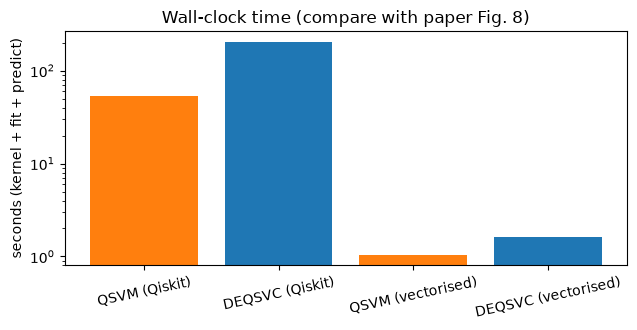

In [19]:
red, rg = "fastica", "pm1"
Atr, Ate = prep0["enc"][(red, rg)]; ytr, yte = prep0["y_train"], prep0["y_test"]
n_chk = min(QISKIT_CHECK_N, len(Atr)); sub = np.random.default_rng(SEED).choice(len(Atr), n_chk, replace=False)
qk = FidelityStatevectorKernel(feature_map=fm)

# 1. kernel matrices agree (on 150 flows: Qiskit's loop over pairs is slow)
t0 = time.perf_counter(); K_qiskit = qk.evaluate(Atr[sub[:150]]); t_k = seconds_since(t0)
S150 = zz_states(Atr[sub[:150]])
print(f"Qiskit kernel of 150 flows in {t_k:.1f} s | max |difference| to the vectorised kernel: {np.abs(K_qiskit - fidelity(S150, S150)).max():.2e}")
assert np.allclose(K_qiskit, fidelity(S150, S150), atol=1e-10)

# 2. dual QSVC
t0 = time.perf_counter(); qsvc = QSVC(quantum_kernel=qk, C=DUAL_C_DEFAULT).fit(Atr[sub], ytr[sub]); p_qsvc = qsvc.predict(Ate); t_qsvc = seconds_since(t0)
S = zz_states(Atr[sub]); p_hand = SVC(kernel="precomputed", C=DUAL_C_DEFAULT).fit(fidelity(S, S), ytr[sub]).predict(fidelity(zz_states(Ate), S))
print(f"QSVC (Qiskit) on {n_chk} flows: {t_qsvc:.1f} s, accuracy {accuracy_score(yte, p_qsvc):.4f} | identical to SVC on the hand-made kernel: {np.array_equal(p_qsvc, p_hand)}")
assert np.array_equal(p_qsvc, p_hand)

# 3. PegasosQSVC
t0 = time.perf_counter()
peg = PegasosQSVC(quantum_kernel=qk, C=PEG_C_DEFAULT, num_steps=QISKIT_STEPS, seed=SEED).fit(Atr[sub], ytr[sub]); p_peg = peg.predict(Ate); t_peg = seconds_since(t0)
alpha_y = pegasos_fit(fidelity(S, S) + 1.0, ytr[sub], PEG_C_DEFAULT, QISKIT_STEPS, SEED)
p_peg_hand = (attack_score("pegasos", alpha_y, fidelity(zz_states(Ate), S)) > 0).astype(int)
print(f"PegasosQSVC (Qiskit, {QISKIT_STEPS} steps) on {n_chk} flows: {t_peg:.1f} s, accuracy {accuracy_score(yte, p_peg):.4f} | identical to pegasos_fit: {np.array_equal(p_peg, p_peg_hand)}")
assert np.array_equal(p_peg, p_peg_hand)

# wall-clock of the vectorised route for the same two models on the full training set (kernel + fit + predict)
t0 = time.perf_counter(); QuantumKernelClassifier("pegasos", 1.0, PEG_C_DEFAULT, PEG_STEPS_DEFAULT, SEED).fit(Atr, ytr).predict(Ate); t_vec_peg = seconds_since(t0)
t0 = time.perf_counter(); QuantumKernelClassifier("dual", 1.0, DUAL_C_DEFAULT, 0, SEED).fit(prep0["enc"][("pca", "pm1")][0], ytr).predict(prep0["enc"][("pca", "pm1")][1]); t_vec_dual = seconds_since(t0)
timing = pd.DataFrame({"route": ["Qiskit QSVC (QSVM)", "Qiskit PegasosQSVC (DEQSVC)", "vectorised dual QSVC (QSVM)", "vectorised Pegasos (DEQSVC)"],
                       "training flows": [n_chk, n_chk, len(Atr), len(Atr)], "Pegasos steps": [0, QISKIT_STEPS, 0, PEG_STEPS_DEFAULT], "seconds": [t_qsvc, t_peg, t_vec_dual, t_vec_peg]})
display(timing.round(2))
fig, ax = plt.subplots(figsize=(6.5, 3.4)); ax.bar(["QSVM (Qiskit)", "DEQSVC (Qiskit)", "QSVM (vectorised)", "DEQSVC (vectorised)"], timing.seconds, color=["tab:orange", "tab:blue", "tab:orange", "tab:blue"])
ax.set_yscale("log"); ax.set_ylabel("seconds (kernel + fit + predict)"); ax.set_title("Wall-clock time (compare with paper Fig. 8)"); plt.xticks(rotation=12); plt.tight_layout(); plt.show()

## 9. A noisy-device proxy for the paper's IBM Quantum result (Table VI)

The paper ran DEQSVC on the 7-qubit `ibm_oslo` machine and obtained 92 % accuracy. That machine has been retired and no hardware is used here. As a proxy the *compute-uncompute* circuit of Section "Quantum Circuit Architecture" is transpiled to the `FakeOslo` device (qubits 0 and 1), simulated with Aer's noise model built from that device's calibration data with `SHOTS = 4000` shots per kernel entry, and the noisy kernel is fed to the same two trainers. Because every kernel entry is a circuit, only a small subset (`NOISY_TRAIN` training and `NOISY_TEST` test flows) is affordable; the same flows are also classified with the exact kernel so that the effect of noise is visible. This is a proxy, not a reproduction of the hardware claim: the real device had drifting calibration, queueing and job failures that a static noise model does not capture.

In [20]:
from qiskit_ibm_runtime.fake_provider import FakeOslo
from qiskit_aer import AerSimulator
fake = FakeOslo(); sim = AerSimulator.from_backend(fake)
tq = transpile(kernel_template, sim, initial_layout=[0, 1], optimization_level=1, seed_transpiler=SEED)
print("transpiled for FakeOslo (physical qubits 0 and 1 of the 7-qubit device): depth", tq.depth(), "| gates", dict(tq.count_ops()))
pnames = list(xs) + list(zs)

itr_n = np.random.default_rng(SEED).choice(np.where(ytr == 0)[0], NOISY_TRAIN // 2, replace=False)
itr_a = np.random.default_rng(SEED).choice(np.where(ytr == 1)[0], NOISY_TRAIN // 2, replace=False)
ite_n = np.random.default_rng(SEED).choice(np.where(yte == 0)[0], NOISY_TEST // 2, replace=False)
ite_a = np.random.default_rng(SEED).choice(np.where(yte == 1)[0], NOISY_TEST // 2, replace=False)
A_n_tr, y_n_tr = Atr[np.r_[itr_n, itr_a]], ytr[np.r_[itr_n, itr_a]]
A_n_te, y_n_te = Ate[np.r_[ite_n, ite_a]], yte[np.r_[ite_n, ite_a]]

def noisy_kernel(A, B, symmetric):
    pairs = [(i, j) for i in range(len(A)) for j in (range(i + 1, len(B)) if symmetric else range(len(B)))]
    circs = [tq.assign_parameters(dict(zip(pnames, np.r_[A[i], B[j]]))) for i, j in pairs]
    out = []
    for s in range(0, len(circs), 500):
        res_ = sim.run(circs[s:s + 500], shots=SHOTS, seed_simulator=SEED + s).result()
        out += [res_.get_counts(k).get("00", 0) / SHOTS for k in range(len(circs[s:s + 500]))]
    K = np.zeros((len(A), len(B)))
    for (i, j), v in zip(pairs, out):
        K[i, j] = v
        if symmetric: K[j, i] = v
    if symmetric: np.fill_diagonal(K, 1.0)
    return K

t0 = time.perf_counter()
Kn_tr = noisy_kernel(A_n_tr, A_n_tr, True); Kn_te = noisy_kernel(A_n_te, A_n_tr, False)
print(f"{len(A_n_tr) * (len(A_n_tr) - 1) // 2 + len(A_n_te) * len(A_n_tr)} noisy circuits x {SHOTS} shots in {seconds_since(t0):.0f} s")
S_t = zz_states(A_n_tr); Ke_tr, Ke_te = fidelity(S_t, S_t), fidelity(zz_states(A_n_te), S_t)
print("mean |noisy - exact| kernel entry:", round(float(np.abs(Kn_te - Ke_te).mean()), 4), "| mean off-diagonal exact kernel value:", round(float(Ke_tr[~np.eye(len(Ke_tr), dtype=bool)].mean()), 4))
noisy_rows = []
for name, trainer, C, steps in (("DEQSVC (Pegasos)", "pegasos", PEG_C_DEFAULT, PEG_STEPS_DEFAULT), ("QSVM-style dual", "dual", DUAL_C_DEFAULT, 0)):
    for kind, (Ktr, Kte) in (("exact kernel", (Ke_tr, Ke_te)), ("noisy kernel (FakeOslo, 4000 shots)", (Kn_tr, Kn_te))):
        m = fit_model(trainer, Ktr, y_n_tr, C, steps, SEED); p = (attack_score(trainer, m, Kte) > 0).astype(int)
        noisy_rows.append(dict(model=name, kernel=kind, n_train=len(A_n_tr), n_test=len(A_n_te), **metrics(y_n_te, p)))
noisy_df = pd.DataFrame(noisy_rows); display(noisy_df.round(4))

if IBM_TOKEN:    # optional real hardware: the same transpiled circuits on a real backend (not executed in the committed run)
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
    service = QiskitRuntimeService(channel="ibm_quantum_platform", token=IBM_TOKEN)
    backend = service.least_busy(operational=True, simulator=False, min_num_qubits=2)
    print("real hardware backend:", backend.name, "- transpile `kernel_template` for it and submit with SamplerV2 as in Section 9")
else:
    print("IBM_TOKEN is empty: the real-hardware cell is skipped.")

transpiled for FakeOslo (physical qubits 0 and 1 of the 7-qubit device): depth 55 | gates {'rz': 56, 'sx': 16, 'cx': 14, 'measure': 2, 'barrier': 1}


790 noisy circuits x 4000 shots in 122 s
mean |noisy - exact| kernel entry: 0.0636 | mean off-diagonal exact kernel value: 0.5163


,model,kernel,n_train,n_test,accuracy,recall,precision,f1,error
0,DEQSVC (Pegasos),exact kernel,20,30,1.0000,1.0,1.0000,1.0000,0.0000
1,DEQSVC (Pegasos),"noisy kernel (FakeOslo, 4000 shots)",20,30,1.0000,1.0,1.0000,1.0000,0.0000
2,QSVM-style dual,exact kernel,20,30,0.9667,1.0,0.9375,0.9677,0.0333
3,QSVM-style dual,"noisy kernel (FakeOslo, 4000 shots)",20,30,0.9667,1.0,0.9375,0.9677,0.0333


IBM_TOKEN is empty: the real-hardware cell is skipped.


## 10. Paper versus this notebook

Each row is one number of the paper. The verdict is **reproduced** when the mean over the repeated runs of this notebook is within 2 accuracy points (0.02 for recall, precision, F-score, error) of the paper, **exceeded** when it is more than that above the paper's (below for the error rate), **not reached** otherwise, and **cannot be checked** when the quantity needs something this notebook cannot run (other authors' models, real hardware, the authors' machine). For the headline numbers both the as-published and the tuned variant are shown. Run 0 is the single paper-like run.

In [21]:
def v(paper, ours, tol=0.02, lower_better=False):
    d = ours - paper
    if abs(d) <= tol: return "reproduced"
    better = (d < 0) if lower_better else (d > 0)
    return f"exceeded by {abs(d):.3f}" if better else f"not reached (gap {abs(d):.3f})"

DEQ = dict(family="quantum", reduction="fastica", scaling="pm1", model="Pegasos")
QSV = dict(family="quantum", reduction="pca", scaling="pm1", model="Dual QSVC")
rows = []
for variant in ("as-published", "tuned"):
    for metric, p in (("accuracy", 0.9949), ("recall", 0.99), ("precision", 0.99), ("f1", 0.99), ("error", 0.005)):
        o = mean_of(metric, variant=variant, **DEQ)
        rows.append(dict(claim=f"Table IV DEQSVC {metric} ({variant})", paper=p, notebook_mean=round(o, 4), notebook_run0=round(float(pick(run=0, variant=variant, **DEQ)[metric].iloc[0]), 4),
                         verdict=v(p, o, lower_better=(metric == "error"))))
for variant in ("as-published", "tuned"):
    for metric, p in (("accuracy", 0.9714), ("recall", 0.9614), ("precision", 0.9719), ("f1", 0.96), ("error", 0.0286)):
        o = mean_of(metric, variant=variant, **QSV)
        rows.append(dict(claim=f"Table IV QSVM (PCA, dual) {metric} ({variant})", paper=p, notebook_mean=round(o, 4), notebook_run0=round(float(pick(run=0, variant=variant, **QSV)[metric].iloc[0]), 4),
                         verdict=v(p, o, lower_better=(metric == "error"))))
for variant in ("as-published", "tuned"):
    o = mean_of("accuracy", variant=variant, family="quantum", reduction="pca", scaling="pm1", model="Pegasos")
    rows.append(dict(claim=f"Section IV.B: DEQSVC with PCA gives 72 % ({variant})", paper=0.72, notebook_mean=round(o, 4),
                     notebook_run0=round(float(pick(run=0, variant=variant, family="quantum", reduction="pca", scaling="pm1", model="Pegasos").accuracy.iloc[0]), 4), verdict=v(0.72, o)))
res_tab = pd.DataFrame(rows)

claims = []
for variant in ("as-published", "tuned"):
    gap = mean_of("accuracy", variant=variant, **DEQ) - mean_of("accuracy", variant=variant, **QSV)
    claims.append(dict(claim=f"DEQSVC more accurate than QSVM ({variant})", paper="+2.35 points", notebook=f"{100 * gap:+.2f} points",
                       verdict="tie (within 1 point)" if abs(gap) < 0.01 else ("reproduced (same direction)" if gap > 0 else "not reproduced (QSVM ahead)")))
    gap = mean_of("accuracy", variant=variant, **DEQ) - mean_of("accuracy", variant=variant, family="quantum", reduction="pca", scaling="pm1", model="Pegasos")
    claims.append(dict(claim=f"FastICA more accurate than PCA inside DEQSVC ({variant})", paper="+27.5 points (99.49 vs 72)", notebook=f"{100 * gap:+.2f} points",
                       verdict="tie (within 1 point)" if abs(gap) < 0.01 else ("reproduced (same direction)" if gap > 0 else "not reproduced (PCA ahead)")))
best_cl = max(("SVC-RBF tuned", "RandomForest"), key=lambda m: mean_of("accuracy", family="classical", reduction="fastica", scaling="pm1", model=m))
gap = mean_of("accuracy", variant="tuned", **DEQ) - mean_of("accuracy", family="classical", reduction="fastica", scaling="pm1", model=best_cl)
claims.append(dict(claim="DEQSVC outperforms common IDS algorithms (abstract); our classical baseline on the same 2 inputs", paper="DEQSVC best", notebook=f"DEQSVC tuned minus {best_cl} = {100 * gap:+.2f} points",
                   verdict="tie (within 1 point)" if abs(gap) < 0.01 else ("reproduced" if gap > 0 else "not reproduced (classical ahead)")))
def sens(**kw):
    d = res_s
    for k, val in kw.items(): d = d[d[k] == val]
    return float(d.accuracy.mean())
for text, a, b in (("DEQSVC vs QSVM (PCA, dual)", dict(family="quantum", reduction="fastica", scaling="pm1", model="Pegasos", variant="tuned"), dict(family="quantum", reduction="pca", scaling="pm1", model="Dual QSVC", variant="tuned")),
                   ("FastICA vs PCA inside DEQSVC", dict(family="quantum", reduction="fastica", scaling="pm1", model="Pegasos", variant="tuned"), dict(family="quantum", reduction="pca", scaling="pm1", model="Pegasos", variant="tuned")),
                   ("DEQSVC vs tuned RBF-SVM on the same FastICA input", dict(family="quantum", reduction="fastica", scaling="pm1", model="Pegasos", variant="tuned"), dict(family="classical", reduction="fastica", scaling="pm1", model="SVC-RBF tuned"))):
    gap = sens(**a) - sens(**b)
    claims.append(dict(claim=f"Sensitivity analysis without Inbound/Protocol: {text}", paper="(not in the paper)", notebook=f"{100 * sens(**a):.2f} % vs {100 * sens(**b):.2f} % ({100 * gap:+.2f} points)",
                       verdict="tie (within 1 point)" if abs(gap) < 0.01 else ("first ahead" if gap > 0 else "second ahead")))
t_q, t_c = timing.seconds[1], timing.seconds[0]
claims.append(dict(claim="Table IV wall-clock: DEQSVC (92 s) faster than QSVM (190 s)", paper="92 s vs 190 s", notebook=f"Qiskit route on {n_chk} flows, {QISKIT_STEPS} Pegasos steps: Pegasos {t_q:.1f} s vs QSVC {t_c:.1f} s",
                   verdict="reproduced (same direction)" if t_q < t_c else "not reproduced (Pegasos slower here)"))
for name, a in (("QNN [15]", "86 %"), ("quantum ensemble [11]", "65.35 %"), ("QASVM [17]", "76.75 %")):
    claims.append(dict(claim=f"Benchmark {name}", paper=a, notebook="not re-implemented", verdict="cannot be checked"))
nz = noisy_df[(noisy_df.model == "DEQSVC (Pegasos)") & noisy_df.kernel.str.startswith("noisy")].iloc[0]
claims.append(dict(claim="Table VI: DEQSVC on ibm_oslo gives 92 % (a drop of 7.5 points from the simulator)", paper="92 %",
                   notebook=f"FakeOslo noise proxy on {nz.n_test} test flows: {100 * nz.accuracy:.1f} %", verdict="cannot be checked (no hardware); proxy shown"))
display(res_tab); display(pd.DataFrame(claims))
print("MODE: FAST_MODE =", FAST_MODE, "| runs:", N_RUNS)

,claim,paper,notebook_mean,notebook_run0,verdict
0,Table IV DEQSVC accuracy (as-published),0.9949,0.9983,1.000,reproduced
1,Table IV DEQSVC recall (as-published),0.9900,0.9967,1.000,reproduced
2,Table IV DEQSVC precision (as-published),0.9900,1.0000,1.000,reproduced
3,Table IV DEQSVC f1 (as-published),0.9900,0.9983,1.000,reproduced
4,Table IV DEQSVC error (as-published),0.0050,0.0017,0.000,reproduced
5,Table IV DEQSVC accuracy (tuned),0.9949,0.9983,1.000,reproduced
6,Table IV DEQSVC recall (tuned),0.9900,0.9967,1.000,reproduced
7,Table IV DEQSVC precision (tuned),0.9900,1.0000,1.000,reproduced
8,Table IV DEQSVC f1 (tuned),0.9900,0.9983,1.000,reproduced
9,Table IV DEQSVC error (tuned),0.0050,0.0017,0.000,reproduced


,claim,paper,notebook,verdict
0,DEQSVC more accurate than QSVM (as-published),+2.35 points,+0.00 points,tie (within 1 point)
1,FastICA more accurate than PCA inside DEQSVC (...,+27.5 points (99.49 vs 72),+0.00 points,tie (within 1 point)
2,DEQSVC more accurate than QSVM (tuned),+2.35 points,-0.17 points,tie (within 1 point)
3,FastICA more accurate than PCA inside DEQSVC (...,+27.5 points (99.49 vs 72),+0.17 points,tie (within 1 point)
4,DEQSVC outperforms common IDS algorithms (abst...,DEQSVC best,DEQSVC tuned minus SVC-RBF tuned = -0.17 points,tie (within 1 point)
5,Sensitivity analysis without Inbound/Protocol:...,(not in the paper),98.00 % vs 100.00 % (-2.00 points),second ahead
6,Sensitivity analysis without Inbound/Protocol:...,(not in the paper),98.00 % vs 100.00 % (-2.00 points),second ahead
7,Sensitivity analysis without Inbound/Protocol:...,(not in the paper),98.00 % vs 99.83 % (-1.83 points),second ahead
8,Table IV wall-clock: DEQSVC (92 s) faster than...,92 s vs 190 s,"Qiskit route on 300 flows, 300 Pegasos steps: ...",not reproduced (Pegasos slower here)
9,Benchmark QNN [15],86 %,not re-implemented,cannot be checked


MODE: FAST_MODE = True | runs: 3


## Reading the paper critically

**On this file the task is almost trivial, so the experiment cannot rank the variants.** A random forest, a tuned RBF-SVM and every quantum variant reach 99-100 % on the 200 test flows, with two numbers per flow as well as with all 39 features (Section 4). Three single columns (`Flow Bytes/s`, `Total Length of Fwd Packets`, `Max Packet Length`) separate the classes above 90 % with one split, and the capture-direction flag `Inbound` and `Protocol` do nearly as well. Whatever the circuit does, there is little room for it to matter: the paper's DEQSVC number (99.49 %) is reproduced, but so is the same number for a classical RBF-SVM on the same two inputs, and the notebook's "DEQSVC outperforms common IDS algorithms" check ends in a tie. The paper has no classical baseline on the same two features; without one, "outperforms" cannot be separated from "the data is easy".

**The 72 % PCA result is not reproduced, and the explanation given for it does not hold.** With PCA instead of FastICA the same two-qubit, four-repetition pipeline gives 99.7-100 % (Section 10). The paper argues that PCA finds "uncorrelated" and ICA "independent" components and that "uncorrelated variables have a linear relationship"; the second statement is wrong (uncorrelated means no *linear* relationship). More to the point, scikit-learn's `FastICA` with two components first whitens the data (PCA plus a rescaling to unit variance) and then only rotates the plane. The check after the scatter plots shows that the FastICA scores are an exact orthogonal map (orthogonality error 0.0, relative residual 0.0, rotation of about 35 degrees) of the whitened PCA scores. After `MinMaxScaler` has removed the per-axis scale, "FastICA versus PCA" is therefore nothing but a rotation of the input plane, which changes the kernel a little (the ZZ phase `(pi - x0)(pi - x1)` is not rotation invariant) and not the information content. A 27-point gap cannot come from that rotation alone; something else in the authors' PCA run (unscaled PCA scores entering the circuit, a different bandwidth, a different split) must have been different, and the paper does not record it.

**The QSVM benchmark is not defined well enough to be reproduced.** Table II gives a 4500 / 500 split and two qubits but not the reduction, angle range or `C`. Our best-guess QSVM (PCA, (-1, 1), dual QSVC) reaches 99.8-100 %, i.e. 2.7-2.9 points above the paper's 97.14 %; the "DEQSVC beats QSVM by 2.35 points" claim is a tie here. Pegasos itself is not an advantage either: it is a stochastic solver, and with 1000 steps it is the noisiest variant (standard deviation up to 2-3 points in the sensitivity analysis), while the dual solver is deterministic and at least as accurate. The timing claim (92 s for DEQSVC, 190 s for QSVM) is reversed in Qiskit's own classes: `PegasosQSVC` evaluates the kernel flow by flow in Python and was several times slower than `QSVC` in Section 8, while on the vectorised simulator both take about a second.

**The numbers of Table IV are internally odd.** With 200 test flows one flow is 0.5 accuracy points, so 99.49 % is not attainable (195 of 196 would give it); 97.14 % and 2.86 % are 34 / 35 and 1 / 35; the text gives the QSVM error as 3.31 % while the table says 2.86 %, and the quantum-ensemble error as 34.65 % versus 34.6 %. The file also has only 1,612 benign flows, so a 5000-flow sample cannot be balanced: if the authors' sample was mostly attack flows, plain accuracy is flattered by the majority class. The paper does not say.

**Leakage and identifiers.** Algorithm 1 standardises before splitting (the test flows influence the scaler); here every fitted step uses the training flows only. The paper's "80 features" may include the port numbers (it does not say); the source port alone identifies LDAP reflection traffic (port 389), so they were removed here. Sections 4 and 7 show that even without ports the data separates easily. The sensitivity analysis without `Inbound` and `Protocol` is the only place where the variants separate at all: the classical models stay at 99.8-100 % while some quantum variants (especially Pegasos with the bandwidth left at 1) drop to 97-98 %, and the tuned dual QSVC is back at 99.8-100 %. That is a statement about solver and bandwidth, not about FastICA.

**Hardware.** The paper attributes the drop from 99.49 % to 92 % on `ibm_oslo` to noise. The noisy proxy of Section 9 (FakeOslo noise model, 4000 shots) perturbs the kernel entries by 0.06 on average yet leaves the accuracy on the 30 (fast mode) test flows unchanged; a static noise model on a tiny subset does not reproduce a 7.5-point loss, and the real run's queueing, failed jobs and calibration drift are not modelled. The hardware claim stays unchecked.

**What this committed run is.** It is the `FAST_MODE = True` run (3 repeated runs, small grids, 300-flow Qiskit cross-check with 300 Pegasos steps, 50-flow noisy proxy, 3 sensitivity runs). It took 36 minutes of wall-clock time on a laptop that was shared with many other jobs (about 10 minutes on an idle machine); the full-mode budgets (10 runs, 5 bandwidths, 500-flow Qiskit check, 100-flow noisy proxy, 5 sensitivity runs) were not run for the committed notebook because under that load they would have exceeded 90 minutes. With three runs and 200 test flows, a difference of less than one or two points between two variants is not meaningful.

## Exercises

1. **Bandwidth.** Set `BW_GRID = [1.0]` so that the scaled flows enter the circuit as raw angles, as the paper implies. Which encodings collapse, and what does the kernel heat-map of Section 6 look like?
2. **Repetitions.** Change `ZZ_REPS` from 4 to 1 and 2. Does the DEQSVC-versus-QSVM gap change more than the run-to-run standard deviation of Section 7? (The fast simulator `zz_states` takes `reps` as an argument; the circuit drawing follows the constant.)
3. **Rotation only.** Replace `FastICA` by `PCA(whiten=True)` followed by a rotation of 30 degrees (`np.array([[c, -s], [s, c]])`). Do you obtain the FastICA numbers? What does that say about the paper's "independent versus uncorrelated" argument?
4. **Leakage.** Add `Source Port` and `Destination Port` back to the feature set (remove them from `IDENT_COLUMNS`, delete `qc289_data`) and rerun. How do the classical baselines react, and what would this have done to the paper's 99.49 %?
5. **Hardware realism.** Increase `NOISY_TRAIN` and `NOISY_TEST` (full mode) and change `SHOTS` to 400 and 40,000. How does the accuracy of the noisy kernel depend on the shot count, and is the noisy kernel still positive semi-definite (`np.linalg.eigvalsh`)?